# **Aprendizaje por refuerzos** - FrozenLake y LunarLander (Gymnasium)

## Tarea: Implementar Agentes Q-Learning y DQN

### Objetivos:
1. Implementar el algoritmo Q-Learning
2. Implementar el algoritmo DQN
3. Entrenar y evaluar ambos agentes
4. Comparar el rendimiento de ambos enfoques


In [7]:
# Instalar paquetes requeridos
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

%pip install swig matplotlib gymnasium torch pygame pandas seaborn --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# Importar las bibliotecas
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pygame
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import deque, namedtuple
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import concurrent.futures
import os

C:\Users\hezek\AppData\Roaming\Python\Python312\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


La siguiente celda permite ejecutar un juego de Frozen Lake *determinista* para jugar con el teclado.

Utilize las teclas de dirección (flechas) o asdw para comandar al agente.


In [9]:
def jugar_frozen_lake(env):
    env.reset()
    
    print("Controles:")
    print("W - Arriba")
    print("S - Abajo") 
    print("A - Izquierda")
    print("D - Derecha")
    print("Q - Salir")
    print("Presione cualquier tecla para empezar...")
    
    pygame.init()
    pygame.display.set_caption("FrozenLake - Juego Interactivo")
    
    clock = pygame.time.Clock()
    ejecutando = True
    
    while ejecutando:
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                ejecutando = False
            elif event.type == pygame.KEYDOWN:
                if event.key == pygame.K_q or event.key == pygame.K_ESCAPE:
                    ejecutando = False
                elif event.key == pygame.K_w or event.key == pygame.K_UP:
                    accion = 3  # Arriba
                elif event.key == pygame.K_s or event.key == pygame.K_DOWN:
                    accion = 1  # Abajo
                elif event.key == pygame.K_a or event.key == pygame.K_LEFT:
                    accion = 0  # Izquierda
                elif event.key == pygame.K_d or event.key == pygame.K_RIGHT:
                    accion = 2  # Derecha
                else:
                    continue
                
                observacion, recompensa, terminado, truncado, info = env.step(accion)
                print(f"Acción: {accion}, Recompensa: {recompensa}, Terminado: {terminado}")
                
                if terminado or truncado:
                    print(f"¡Episodio terminado! Recompensa final: {recompensa}")
                    pygame.time.wait(500)
                    env.reset()
        
        clock.tick(60)
    
    pygame.quit()
    env.close()

env = gym.make('FrozenLake-v1', render_mode='human', is_slippery=False)
# Descomente la línea de abajo para jugar interactivamente
#jugar_frozen_lake(env)

La siguiente celda permite jugar al juego no determinista.

In [10]:
env = gym.make('FrozenLake-v1', map_name="4x4", render_mode='human', is_slippery=True)
# Descomente la línea de abajo para jugar interactivamente
#jugar_frozen_lake(env)

La siguiente clase define la interfaz de los agentes que utilizaremos para jugar al Frozen Lake.


In [11]:
from abc import ABC, abstractmethod

class Agente(ABC):
    
    @abstractmethod
    def elegir_accion(self, estado):
        """Elige una acción dada una observación."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar."""
    
    def __init__(self, espacio_acciones):
        # Se guarda el espacio de acciones para poder elegir acciones al azar
        self.espacio_acciones = espacio_acciones
    
    def elegir_accion(self, estado):
        return self.espacio_acciones.sample()


    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende

# Probar el AgenteAleatorio
env = gym.make('FrozenLake-v1')
agente_aleatorio = AgenteAleatorio(env.action_space)
estado, _ = env.reset()
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()


✓ AgenteAleatorio creado y probado. Acción: 1


In [12]:
from abc import ABC, abstractmethod

class EpsilonStrategy(ABC):
    @abstractmethod
    def decay(self, step: float | None = None) -> float:
        pass

class EpsilonStrExp(EpsilonStrategy):
    def __init__(self, epsilon=1.0, epsilon_min=0.1, decay_rate=0.995):
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.decay_rate = decay_rate

    def decay(self) -> float:
        self.epsilon = max(self.epsilon_min, self.epsilon * self.decay_rate)
        return self.epsilon

class EpsilonStrLinear(EpsilonStrategy):
    def __init__(self, epsilon=1.0, epsilon_min=0.1, decay_steps=1000):
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.decay_steps = decay_steps

    def decay(self) -> float:
        self.epsilon = max(self.epsilon_min, self.epsilon - 1.0 / self.decay_steps)
        return self.epsilon

class EpsilonStrCosine(EpsilonStrategy):
    def __init__(self, epsilon=1.0, epsilon_min=0.1, decay_steps=1000):
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.decay_steps = decay_steps
        self.step = 0

    def decay(self) -> float:
        self.step += 1
        cosine_decay = 0.5 * (1 + np.cos(np.pi * self.step / self.decay_steps))
        self.epsilon = self.epsilon_min + (self.epsilon - self.epsilon_min) * cosine_decay
        return self.epsilon



La siguiente celda define una función para evaluar el desempeño de un agente dado.

In [13]:
# Función de Evaluación de Agentes
def evaluar_agente(agente, env, num_episodios=1000):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.
    
    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
    
    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    victorias = 0
    
    for episodio in range(num_episodios):
        estado, _ = env.reset()
        recompensa_total = 0
        
        while True:
            accion = agente.elegir_accion(estado)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa
            
            if terminado or truncado:
                break
        
        recompensas_totales.append(recompensa_total)
        if recompensa_total > 0:
            victorias += 1
    
    return {
        'recompensas_totales': recompensas_totales,
        'victorias': victorias,
        'tasa_victorias': victorias / num_episodios,
        'recompensa_promedio': np.mean(recompensas_totales),
        'desv_estandar': np.std(recompensas_totales)
    }

def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación de forma formateada."""
    print(f"\n{nombre_agente} - Resultados de Evaluación:")
    print(f"Tasa de Victorias: {resultados['tasa_victorias']:.1%}")
    print(f"Recompensa Promedio: {resultados['recompensa_promedio']:.3f}")
    print(f"Desviación Estándar: {resultados['desv_estandar']:.3f}")
    print(f"Total de Victorias: {resultados['victorias']}")

# Probar función de evaluación
env = gym.make('FrozenLake-v1')
agente_aleatorio = AgenteAleatorio(env.action_space)
resultados = evaluar_agente(agente_aleatorio, env, num_episodios=100)
imprimir_resultados_evaluacion(resultados, "Agente Aleatorio")
env.close()



Agente Aleatorio - Resultados de Evaluación:
Tasa de Victorias: 0.0%
Recompensa Promedio: 0.000
Desviación Estándar: 0.000
Total de Victorias: 0


La siguiente celda define una función para entrenar un agente.

In [14]:
# Función de Entrenamiento de Agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=500, verbose=True):
    """
    Entrena un agente en el entorno.
    
    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
    
    Returns:
        list: Recompensas de episodios
    """
    recompensas_episodios = []
    longitudes_episodios = []
    epsilons_episodios = []
    num_episodios_10 = int(num_episodios / 10)
    #alphas_episodios = []
    
    for episodio in range(num_episodios):
        estado, _ = env.reset()
        recompensa_total = 0
        pasos = 0
        
        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado or truncado)
            
            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1
            
            if terminado or truncado:
                break
        
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        epsilons_episodios.append(agente.epsilon)
        # if isinstance(agente, AgenteQLearning):
        #     alphas_episodios.append(agente.alpha)
        
        if verbose and (episodio + 1) % num_episodios_10 == 0:
            recompensa_promedio = np.mean(recompensas_episodios[-num_episodios_10:])
            longitud_promedio = np.mean(longitudes_episodios[-num_episodios_10:])
            epsilon_promedio = np.mean(epsilons_episodios[-num_episodios_10:])
            #alpha_promedio = np.mean(alphas_episodios[-num_episodios_10:])
            print(f"Episodio {episodio + 1}: Recompensa Promedio = {recompensa_promedio:.3f}, Longitud Promedio = {longitud_promedio:.1f}, Epsilon Promedio = {epsilon_promedio:.3f}")

    return recompensas_episodios, longitudes_episodios, epsilons_episodios

print("✓ Funciones de entrenamiento definidas")



✓ Funciones de entrenamiento definidas


## UTILIDADES 

In [15]:
def graficar_resultados(recompensas, longitudes, epsilons, ventana=1):
    fig, axes = plt.subplots(1, 3, figsize=(18,5))

    axes[0].plot(recompensas)
    axes[0].set_title('Recompensas por Episodio (ventana ' + str(ventana) + ')')
    axes[0].set_xlabel('Episodio')
    axes[0].set_ylabel('Recompensa')

    axes[1].plot(longitudes)
    axes[1].set_title('Longitudes por Episodio (ventana ' + str(ventana) + ')')
    axes[1].set_xlabel('Episodio')
    axes[1].set_ylabel('Longitud')

    axes[2].plot(epsilons)
    axes[2].set_title('Epsilon por Episodio (ventana ' + str(ventana) + ')')
    axes[2].set_xlabel('Episodio')
    axes[2].set_ylabel('Epsilon')

    plt.tight_layout()
    plt.show()

def obtener_heatmap(df_exp, df_lin, map_name, valores="Tasa de victoria"):
    """
    Genera 3 heatmaps por estrategia:
    axes[0]: Gamma vs Alpha/Lr
    axes[1]: Gamma vs Decay
    axes[2]: Alpha/Lr vs Decay
    """
    
    # ======== ESTRATEGIA EXPONENCIAL ========
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    
    # Heatmap 0: Gamma vs Alpha/Lr (promediado sobre Decay)
    df_gamma_alpha = df_exp.groupby(["Gamma", "Alpha/Lr"], as_index=False)[valores].mean()
    pivot0 = df_gamma_alpha.pivot(index="Gamma", columns="Alpha/Lr", values=valores)
    sns.heatmap(pivot0, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0, vmax=1, 
                cbar_kws={"label": valores}, ax=axes[0])
    axes[0].set_title(f"Gamma vs Alpha/Lr - Exp ({map_name})")
    axes[0].set_xlabel("Alpha/Lr")
    axes[0].set_ylabel("Gamma")
    
    # Heatmap 1: Gamma vs Decay (promediado sobre Alpha/Lr)
    df_gamma_decay = df_exp.groupby(["Gamma", "Decay"], as_index=False)[valores].mean()
    pivot1 = df_gamma_decay.pivot(index="Gamma", columns="Decay", values=valores)
    sns.heatmap(pivot1, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0, vmax=1, 
                cbar_kws={"label": valores}, ax=axes[1])
    axes[1].set_title(f"Gamma vs Decay - Exp ({map_name})")
    axes[1].set_xlabel("Decay")
    axes[1].set_ylabel("Gamma")
    
    # Heatmap 2: Alpha/Lr vs Decay (promediado sobre Gamma)
    df_alpha_decay = df_exp.groupby(["Alpha/Lr", "Decay"], as_index=False)[valores].mean()
    pivot2 = df_alpha_decay.pivot(index="Alpha/Lr", columns="Decay", values=valores)
    sns.heatmap(pivot2, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0, vmax=1, 
                cbar_kws={"label": valores}, ax=axes[2])
    axes[2].set_title(f"Alpha/Lr vs Decay - Exp ({map_name})")
    axes[2].set_xlabel("Decay")
    axes[2].set_ylabel("Alpha/Lr")
    
    plt.tight_layout()
    plt.show()
    
    # ======== ESTRATEGIA LINEAL ========
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    
    # Heatmap 0: Gamma vs Alpha/Lr (promediado sobre Decay)
    df_gamma_alpha = df_lin.groupby(["Gamma", "Alpha/Lr"], as_index=False)[valores].mean()
    pivot0 = df_gamma_alpha.pivot(index="Gamma", columns="Alpha/Lr", values=valores)
    sns.heatmap(pivot0, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0, vmax=1, 
                cbar_kws={"label": valores}, ax=axes[0])
    axes[0].set_title(f"Gamma vs Alpha/Lr - Lin ({map_name})")
    axes[0].set_xlabel("Alpha/Lr")
    axes[0].set_ylabel("Gamma")
    
    # Heatmap 1: Gamma vs Decay (solo un valor "Lineal", muestra promedio por gamma)
    df_gamma_decay = df_lin.groupby(["Gamma", "Decay"], as_index=False)[valores].mean()
    pivot1 = df_gamma_decay.pivot(index="Gamma", columns="Decay", values=valores)
    sns.heatmap(pivot1, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0, vmax=1, 
                cbar_kws={"label": valores}, ax=axes[1])
    axes[1].set_title(f"Gamma vs Decay - Lin ({map_name})")
    axes[1].set_xlabel("Decay")
    axes[1].set_ylabel("Gamma")
    
    # Heatmap 2: Alpha/Lr vs Decay (promediado sobre Gamma)
    df_alpha_decay = df_lin.groupby(["Alpha/Lr", "Decay"], as_index=False)[valores].mean()
    pivot2 = df_alpha_decay.pivot(index="Alpha/Lr", columns="Decay", values=valores)
    sns.heatmap(pivot2, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0, vmax=1, 
                cbar_kws={"label": valores}, ax=axes[2])
    axes[2].set_title(f"Alpha/Lr vs Decay - Lin ({map_name})")
    axes[2].set_xlabel("Decay")
    axes[2].set_ylabel("Alpha/Lr")
    
    plt.tight_layout()
    plt.show()

def promediar_por_bloques(array, ventana):
    return [
        np.mean(array[i:i+ventana])
        for i in range(0, len(array), ventana)
    ]


# QL TABULAR
## Q-Learning en entornos no deterministas

En entornos estocásticos, ejecutar una acción desde un estado no garantiza llegar siempre al mismo siguiente estado, ni recibir siempre la misma recompensa. Por eso, la actualización de la tabla Q se hace de manera **promediada**, usando un factor de aprendizaje α.

La fórmula clásica de actualización es:

$$
Q(s, a) \leftarrow (1-\alpha) Q(s, a) + \alpha \big[r + \gamma \max_{a'} Q(s', a')\big]
$$

- **α (tasa de aprendizaje):** determina cuánto peso le damos a la nueva información frente a lo aprendido hasta ahora.  
- **r + γ max Q(s', a'):** estimación de la recompensa total esperada al ejecutar la acción.
- En **entornos deterministas**, se puede sobrescribir Q(s, a) directamente porque la acción siempre lleva al mismo estado y recompensa.
- En **entornos no deterministas**, se necesita promediar la experiencia, ya que la acción puede llevar a distintos estados con distintas recompensas. El valor de Q converge así al **valor esperado a largo plazo** de cada acción.


In [16]:
class AgenteQLearning(Agente):
    """Agente que usa el algoritmo Q-Learning."""

    def __init__(self, espacio_estados, espacio_acciones, alpha=0.05, gamma=1, epsilon=1.0, epsilon_strategy: EpsilonStrategy = None):
        self.Q_table = np.zeros((espacio_estados.n, espacio_acciones.n))
        self.alpha = alpha  # Tasa de aprendizaje
        self.gamma = gamma  # Factor de descuento
        self.epsilon = epsilon  # Tasa de exploración inicial
        self.espacio_acciones = espacio_acciones
        self.tam_mapa = int(np.sqrt(espacio_estados.n))  
        self.epsilon_strategy = epsilon_strategy
        
    def elegir_accion(self, estado):
        """Elige una acción usando política epsilon-greedy.""" 
        if np.random.rand() < self.epsilon:
            return np.random.randint(4)  # Exploración
        else:
            return np.argmax(self.Q_table[estado])  # Explotación, accion que maximiza Q
    
            
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Actualiza la tabla Q usando la ecuación de Bellman."""
        max_q = np.max(self.Q_table[siguiente_estado])
        self.Q_table[estado, accion] = (1 - self.alpha) * self.Q_table[estado, accion] + self.alpha * (recompensa + self.gamma * max_q)
        if terminado:
            self.epsilon = self.epsilon_strategy.decay()

    def imprimirQtable(self):
        print("Tabla Q:")
        print(self.Q_table)

    def mostrar_policy(self, env):
        """
        Muestra la política aprendida en el mapa del FrozenLake.
        Flechas solo en casillas 'F' (Frozen); 'H' y 'G' se muestran tal cual.
        """
        # Mapeo de acciones a flechas: 0=izquierda, 1=abajo, 2=derecha, 3=arriba
        acciones_map = ["←", "↓", "→", "↑"]

        # Obtener el mapa original del entorno
        desc = env.unwrapped.desc.astype(str)

        # Crear copia del mapa para mostrar la política
        policy_map = desc.copy()

        # Recorrer filas y columnas del mapa
        for fila in range(self.tam_mapa):
            for col in range(self.tam_mapa):
                estado = fila * self.tam_mapa + col  # convertir fila,col a índice lineal
                if desc[fila, col] == 'F':  # solo actualizar casillas 'Frozen'
                    mejor_accion = np.argmax(self.Q_table[estado])
                    policy_map[fila, col] = acciones_map[mejor_accion]

        print("Policy aprendida:")
        for fila in policy_map:
            print(" ".join(fila))

    def guardar_qtable(self, path="qtable.npy"):
        np.save(path, self.Q_table)
        print(f"Q-table guardada en {path}")

    def cargar_qtable(self, path="qtable.npy"):
        self.Q_table = np.load(path)
        self.epsilon = 0  # Fijar epsilon al mínimo para evaluación
        print(f"Q-table cargada desde {path}")


# DQN

# Deep Q-Network 

## Aprendizaje por Refuerzo con Función de Valor Aproximada

En entornos con **muchos estados**, mantener una **tabla Q** se vuelve inviable. En su lugar, se utiliza una **red neuronal** para aproximar la función Q:

$$
Q(s, a; \theta) \approx \mathbb{E}[R_t \mid s_t = s, a_t = a]
$$

donde $\theta$ son los pesos de la red.


### 1. Actualización de la Red Q

La red se entrena para minimizar la **diferencia entre Q predicho y Q objetivo**:

$$
\mathcal{L}(\theta) = \mathbb{E}_{(s,a,r,s') \sim \text{replay}} \Big[ \big(Q(s,a;\theta) - y \big)^2 \Big]
$$

con el **target**:

$$
y = r + \gamma \max_{a'} Q_{\text{target}}(s', a'; \theta^-)
$$

* **Q(s,a;θ):** predicción de la red principal (`policy_net`) para el estado y acción actuales.
* **Q_target:** red fija (`target_net`) usada para estabilizar el aprendizaje.
* **r + γ max Q_target(s',a'):** estimación de la recompensa futura, equivalente al target en Q-Learning tabular.


### 3. Replay Buffer y Target Network

* **Replay Buffer:** almacena transiciones pasadas $(s,a,r,s',done)$ y permite entrenar sobre **minibatches aleatorios**, rompiendo la correlación temporal.
* **Target Network:** red secundaria con pesos congelados temporalmente, usada para calcular $y$ y evitar inestabilidad.


### 4. Interpretación de la actualización

La actualización de DQN es el análogo **continuo** de la actualización tabular:

* La red ajusta sus pesos θ para que $Q(s,a;\theta) \rightarrow r + \gamma \max Q(s',a';\theta^-)$.
* Esto es equivalente a **promediar experiencias pasadas**, pero usando gradiente descendente sobre todos los minibatches.
* Con suficiente entrenamiento y exploración, Q(s,a;θ) converge al **valor esperado a largo plazo** de cada acción, como en Q-Learning.

In [17]:
class DQN(nn.Module):
    """Clase auxiliar que implementa una Red Q Profunda con una capa oculta."""
    
    def __init__(self, tamano_entrada, tamano_oculto, tamano_salida):
        super(DQN, self).__init__()
        
        self.fc1 = nn.Linear(tamano_entrada, tamano_oculto)
        self.out = nn.Linear(tamano_oculto, tamano_salida)
    
    def forward(self, x):
        x = F.relu(self.fc1(x)) #Func. activación ReLU (Rectified Linear Unit)
        x = self.out(x)         #Capa final no usa activación
        return x                

class AgenteDQN(Agente):
    """Agente de Red Q Profunda."""
    
    def __init__(self,
                 espacio_estados,
                 espacio_acciones,
                 tamano_oculto=32,
                 lr=1e-3,
                 gamma=1,
                 epsilon=1.0,
                 replay_size=10000,
                 batch_size=128,
                 target_update=500,
                 train_freq=15,
                 epsilon_strategy: EpsilonStrategy = None,
                 device=None):
        """
        Args:
            espacio_estados: env.observation_space (discreto)
            espacio_acciones: env.action_space
            tamano_oculto: neuronas en la capa oculta
            lr: learning rate para el optimizador
            gamma: factor de descuento
            epsilon, epsilon_decay, epsilon_min: para epsilon-greedy
            replay_size: capacidad del buffer de replay
            batch_size: tamaño de batch para entrenar
            target_update: cada cuántos pasos copiar la target network
            train_freq: entrenar cada 'train_freq' llamadas a aprender
            device: 'cpu' o 'cuda' (None -> detecta automaticamente)
        """
        # parámetros del entorno
        self.num_states = espacio_estados.n
        self.num_actions = espacio_acciones.n
        
        # hiperparámetros
        self.tamano_oculto = tamano_oculto
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.batch_size = batch_size
        self.target_update = target_update
        self.train_freq = train_freq
        self.epsilon_strategy = epsilon_strategy
        
        # device
        if device is None:
            self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        else:
            self.device = torch.device("cpu")
        

        # redes: policy_net y target_net
        self.policy_net = DQN(self.num_states, self.tamano_oculto, self.num_actions).to(self.device)
        self.target_net = DQN(self.num_states, self.tamano_oculto, self.num_actions).to(self.device)
        
        # inicializar target igual a policy
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()
        
        # optimizador y loss
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=self.lr)
        #self.loss_fn = nn.MSELoss()
        self.loss_fn = nn.SmoothL1Loss()  # Huber loss, más robusta a outliers
        
        # replay buffer
        self.replay_buffer = deque(maxlen=replay_size)
        
        # contadores
        self.step_count = 0  # para updates y frecuencia de entrenamiento
        
        # semilla opcional
        random.seed(0)
        np.random.seed(0)
        torch.manual_seed(0)
    
    def _one_hot(self, estado):
        """Convierte un entero estado -> vector one-hot tensor en device."""
        vec = np.zeros(self.num_states, dtype=np.float32)
        vec[estado] = 1.0
        return torch.from_numpy(vec).to(self.device)
    
    def elegir_accion(self, estado):
        """Elige acción usando política epsilon-greedy."""
        # exploración
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.num_actions)
        
        # explotación: predecir Q-values y tomar argmax
        self.policy_net.eval()
        with torch.no_grad():
            s_t = self._one_hot(estado).unsqueeze(0)  # shape (1, num_states)
            q_vals = self.policy_net(s_t)            # shape (1, num_actions)
            accion = torch.argmax(q_vals, dim=1).item()
        self.policy_net.train()
        return accion
    

    
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """
        Agrega la transición al buffer y entrena la red periódicamente.
        Este método es llamado por el loop de entrenamiento por paso.
        """
        # almacenar transición (s, a, r, s', done)
        self.replay_buffer.append((estado, accion, recompensa, siguiente_estado, float(terminado)))
        self.step_count += 1
        
        # Entrenar cada 'train_freq' pasos (evita entrenar en cada transición)
        if (self.step_count % self.train_freq == 0) and (len(self.replay_buffer) >= self.batch_size):
            self._train_on_batch()
        
        # actualizar target network periódicamente
        if self.step_count % self.target_update == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())
        
        # si terminó el episodio, actualizar epsilon (igual que en Q-table)
        if terminado:
            self.epsilon = self.epsilon_strategy.decay()
    
    def _train_on_batch(self):
        """Muestrea un minibatch y realiza un paso de optimización."""
        batch = random.sample(self.replay_buffer, self.batch_size)
        estados, acciones, recompensas, estados_siguientes, dones = zip(*batch)
        
        # convertir a tensores
        estados = torch.stack([self._one_hot(s) for s in estados])            # (B, num_states)
        estados_siguientes = torch.stack([self._one_hot(s) for s in estados_siguientes])  # (B, num_states)
        acciones = torch.tensor(acciones, dtype=torch.long, device=self.device)           # (B,)
        recompensas = torch.tensor(recompensas, dtype=torch.float32, device=self.device)  # (B,)
        dones = torch.tensor(dones, dtype=torch.float32, device=self.device)              # (B,)
        
        # Q(s,a) predichos por policy_net
        q_preds = self.policy_net(estados)                       # (B, num_actions)
        q_pred_values = q_preds.gather(1, acciones.unsqueeze(1)).squeeze(1)  # (B,)
        
        # target: r + gamma * max_a' Q_target(s', a')  (0 si done)
        with torch.no_grad():
            q_next = self.target_net(estados_siguientes)        # (B, num_actions)
            q_next_max, _ = q_next.max(dim=1)                  # (B,)
            q_targets = recompensas + (1.0 - dones) * (self.gamma * q_next_max)
        
        # loss y optimización
        loss = self.loss_fn(q_pred_values, q_targets)
        self.optimizer.zero_grad()
        loss.backward()
        # opcional: gradient clipping
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), 10.0)
        self.optimizer.step()

    def mostrar_policy(self, env):
        acciones_map = ["←", "↓", "→", "↑"]
        desc = env.unwrapped.desc.astype(str)
        tam_mapa = int(np.sqrt(self.num_states))
        policy_map = desc.copy()
        
        self.policy_net.eval()
        with torch.no_grad():
            all_states = torch.eye(self.num_states, device=self.device)
            q_vals = self.policy_net(all_states)
            mejores = torch.argmax(q_vals, dim=1).cpu().numpy()
        self.policy_net.train()
        
        for fila in range(tam_mapa):
            for col in range(tam_mapa):
                estado = fila * tam_mapa + col
                if desc[fila, col] == 'F':
                    policy_map[fila, col] = acciones_map[mejores[estado]]
        
        print("Policy aprendida (DQN):")
        for fila in policy_map:
            print(" ".join(fila))    

    def guardar_policy(self, path="dqn_policy.pth"):
        torch.save(self.policy_net.state_dict(), path)
        print(f"Policy guardada en {path}")

    def cargar_policy(self, path="dqn_policy.pth"):
        state_dict = torch.load(path, map_location=self.device, weights_only=True)
        self.policy_net.load_state_dict(state_dict)
        self.policy_net.eval()
        self.epsilon = 0  # Fijar epsilon al mínimo para evaluación
        print(f"Policy cargada desde {path}")


### Función para evaluar hiperparámetros

Permite probar distintos valores de **learning rate** ***(lr para DQN, alpha para Tabular)*** y la **tasa de decaimiento de epsilon** (solo estrategía exponencial), así como la **estrategia de decaimiento de epsilon**, ya sea lineal o exponencial.


In [4]:

from concurrent.futures import ThreadPoolExecutor, as_completed
import os


def _run_single(tipo, alpha, decay, gamma, episodios_train, episodios_eval, map_name, estrategia, decay_steps=None, tamano_oculto=16):
    # Definir pasos máximos por episodio según mapa
    max_steps = 500 if map_name == "4x4" else 1000
    # Crear entorno por trabajo (evita compartir env entre hilos)
    env = gym.make("FrozenLake-v1", map_name=map_name, is_slippery=True, render_mode="ansi", max_episode_steps=max_steps)
    try:
        # Estrategia de epsilon
        if estrategia == "Exponencial":
            epsilon_strategy = EpsilonStrExp(epsilon=1.0, epsilon_min=0.01, decay_rate=decay)
        else:
            epsilon_strategy = EpsilonStrLinear(epsilon=1.0, epsilon_min=0.01, decay_steps=decay_steps or episodios_train)

        # Instanciar agente según tipo
        if tipo == "DQN":
            agente = AgenteDQN(env.observation_space, env.action_space, gamma=gamma, lr=alpha, 
                             tamano_oculto=tamano_oculto, epsilon_strategy=epsilon_strategy, device="cpu")
        else:
            agente = AgenteQLearning(env.observation_space, env.action_space, gamma=gamma, alpha=alpha, epsilon_strategy=epsilon_strategy)

        # Entrenar y evaluar
        entrenar_agente(agente, env, num_episodios=episodios_train, verbose=False, max_pasos=max_steps)
        resultados_eval = evaluar_agente(agente, env, num_episodios=episodios_eval)

        resultado = {
            "Estrategia": estrategia,
            "Alpha/Lr": alpha,
            "Decay": decay if estrategia == "Exponencial" else "Lineal",
            "Gamma": gamma,
            "Tasa de victoria": resultados_eval["tasa_victorias"],
            "Recompensa promedio": resultados_eval["recompensa_promedio"],
            "Desviación estándar": resultados_eval["desv_estandar"]
        }
        
        # Añadir tamano_oculto solo para DQN
        if tipo == "DQN":
            resultado["Tamano oculto"] = tamano_oculto
            
        return resultado
    finally:
        env.close()


def test_params(tipo, alphas, decays, gammas, episodios_train, episodios_eval, map_name, tamanos_ocultos=[16], max_workers=None):
    resultados_exp = []
    resultados_lin = []



    # Preparar trabajos: para cada alpha, gamma y tamano_oculto, probar todos los decays exponenciales y una variante lineal
    jobs = []
    for alpha in alphas:
        for gamma in gammas:
            for tamano_oculto in tamanos_ocultos:
                for decay in decays:
                    jobs.append(("Exponencial", alpha, decay, gamma, tamano_oculto))
                jobs.append(("Lineal", alpha, None, gamma, tamano_oculto))

    # Hilos por defecto: núcleos-1 (mínimo 1)
    if max_workers is None:
        max_workers = max(1, (os.cpu_count() or 2) - 1)

    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        futures = [
            ex.submit(_run_single, tipo, alpha, decay, gamma, episodios_train, episodios_eval, map_name, estrategia, episodios_train, tamano_oculto)
            for (estrategia, alpha, decay, gamma, tamano_oculto) in jobs
        ]
        for fut in as_completed(futures):
            res = fut.result()
            if res["Estrategia"] == "Exponencial":
                resultados_exp.append(res)
            else:
                resultados_lin.append(res)

    # DataFrames
    df_exp = pd.DataFrame(resultados_exp)
    df_lin = pd.DataFrame(resultados_lin)
    return df_exp, df_lin


<h2 style="color: #f53b3bff;">Testeo de Hiperparámetros - Q Tabular</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4 </h3>


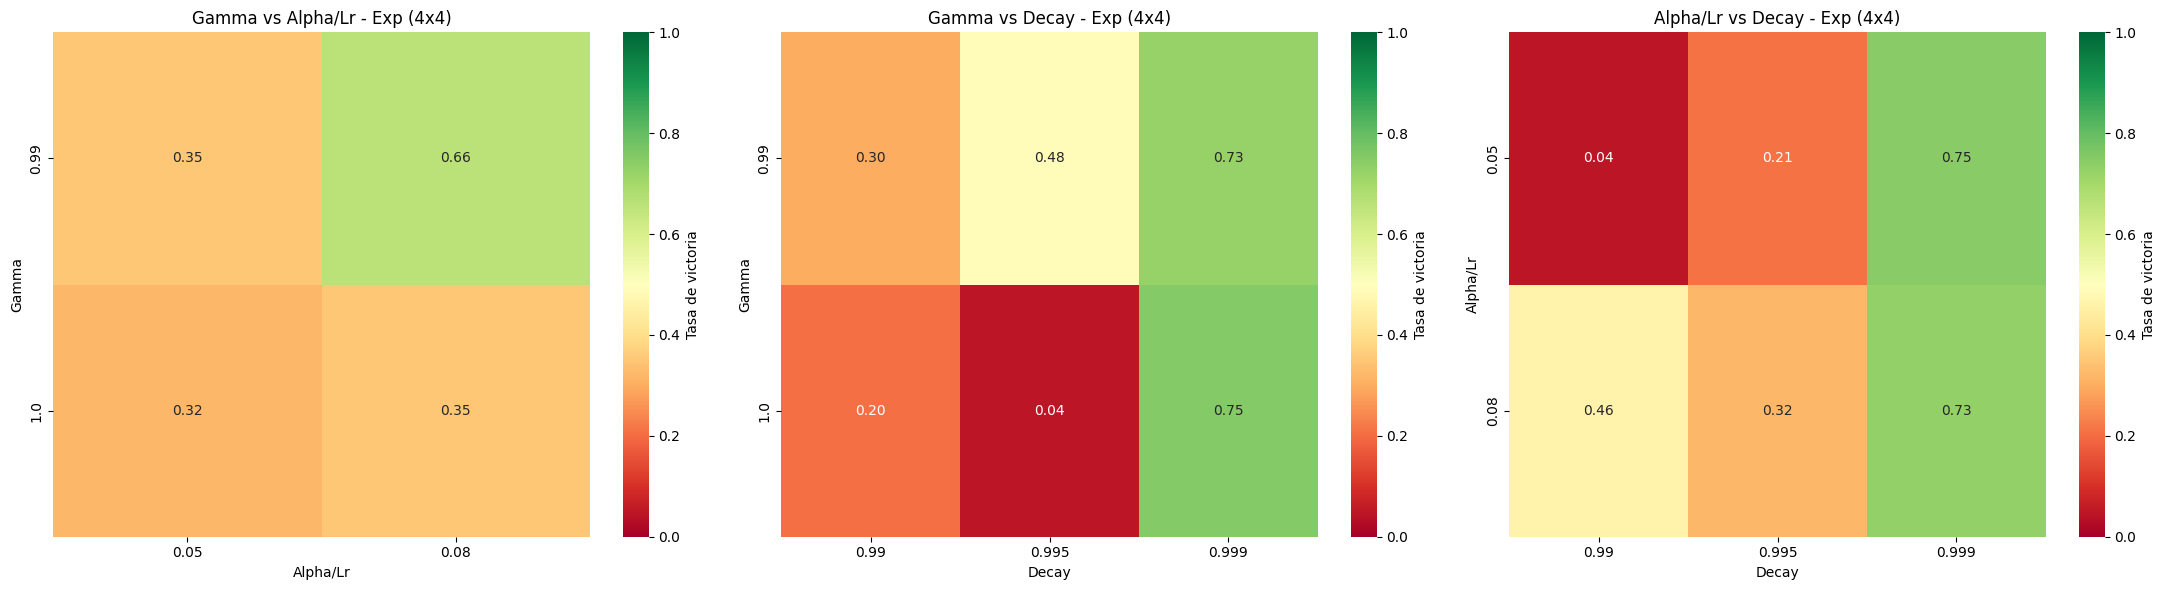

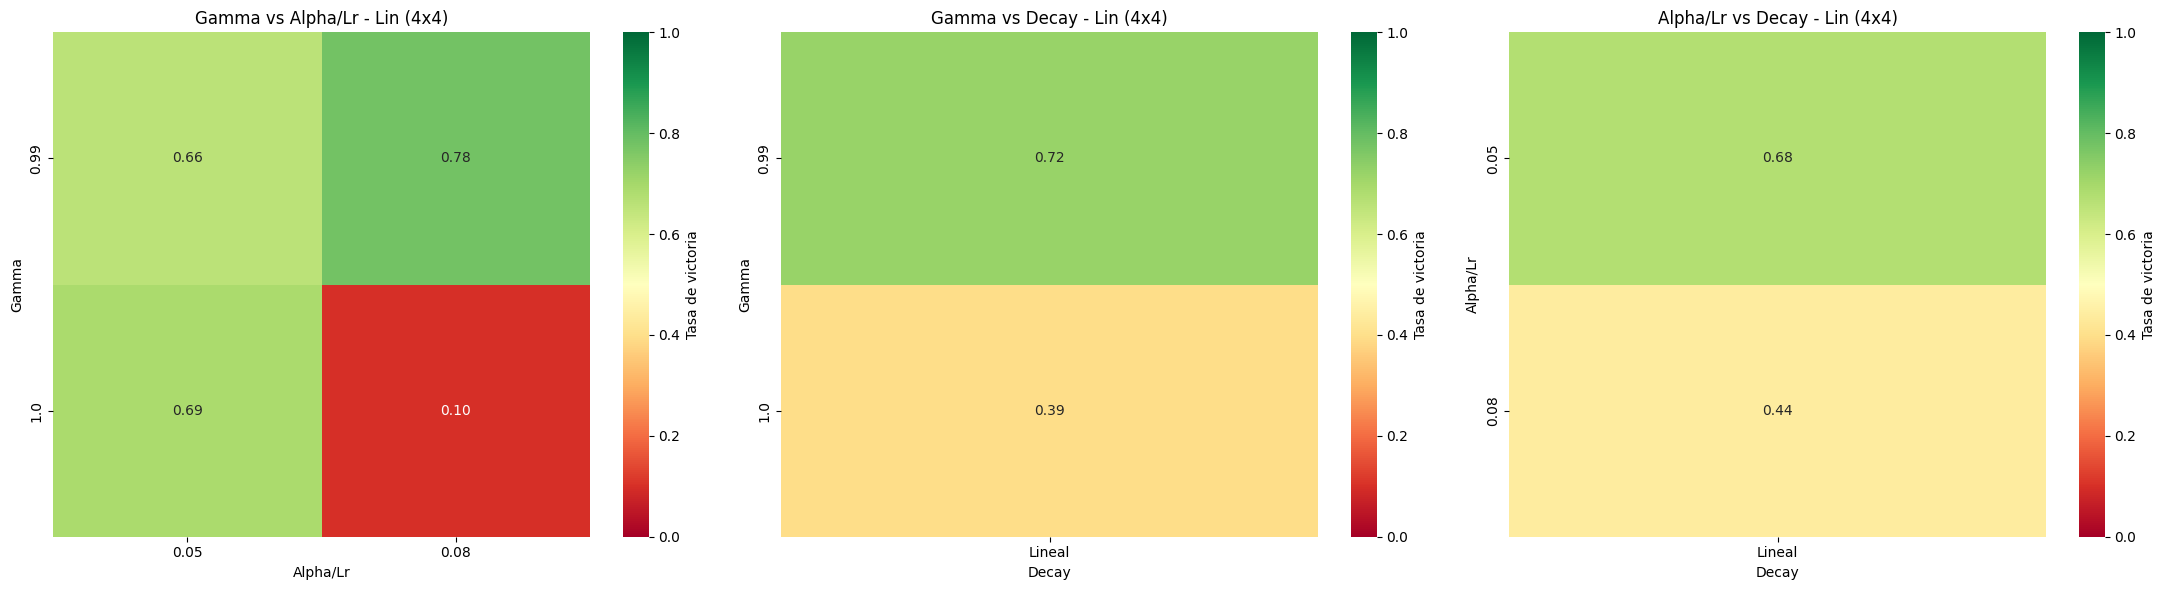


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha/Lr  Decay  Gamma  Tasa de victoria  Recompensa promedio  Desviación estándar
Exponencial     0.050  0.990  1.000             0.050                0.050                0.218
Exponencial     0.050  0.995  1.000             0.090                0.090                0.286
Exponencial     0.050  0.990  0.990             0.040                0.040                0.196
Exponencial     0.080  0.995  1.000             0.000                0.000                0.000
Exponencial     0.050  0.995  0.990             0.330                0.330                0.470
Exponencial     0.080  0.990  1.000             0.360                0.360                0.480
Exponencial     0.050  0.999  1.000             0.810                0.810                0.392
Exponencial     0.050  0.999  0.990             0.680                0.680                0.466
Exponencial     0.080  0.990  0.990             0.560                0.560                0.496


In [18]:
alphas = [0.05, 0.08]
decays = [0.99, 0.995, 0.999]
gammas = [1.0, 0.99]
episodios_train = 5000
episodios_eval = 100
map_name = "4x4"

df_exp, df_lin = test_params("Q", alphas, decays, gammas, episodios_train, episodios_eval, map_name)


obtener_heatmap(df_exp, df_lin, map_name, valores="Tasa de victoria")

# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))


<h2 style="color: #228B22;">Entrenar Agente QL tabular</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

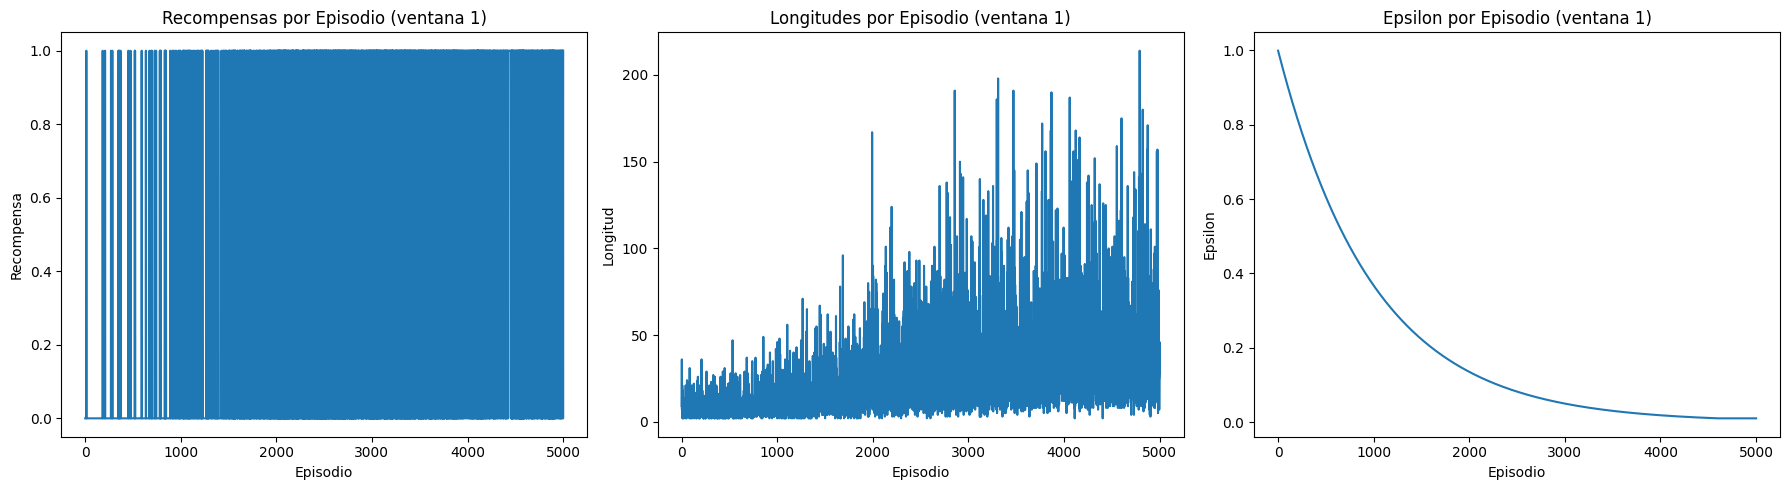

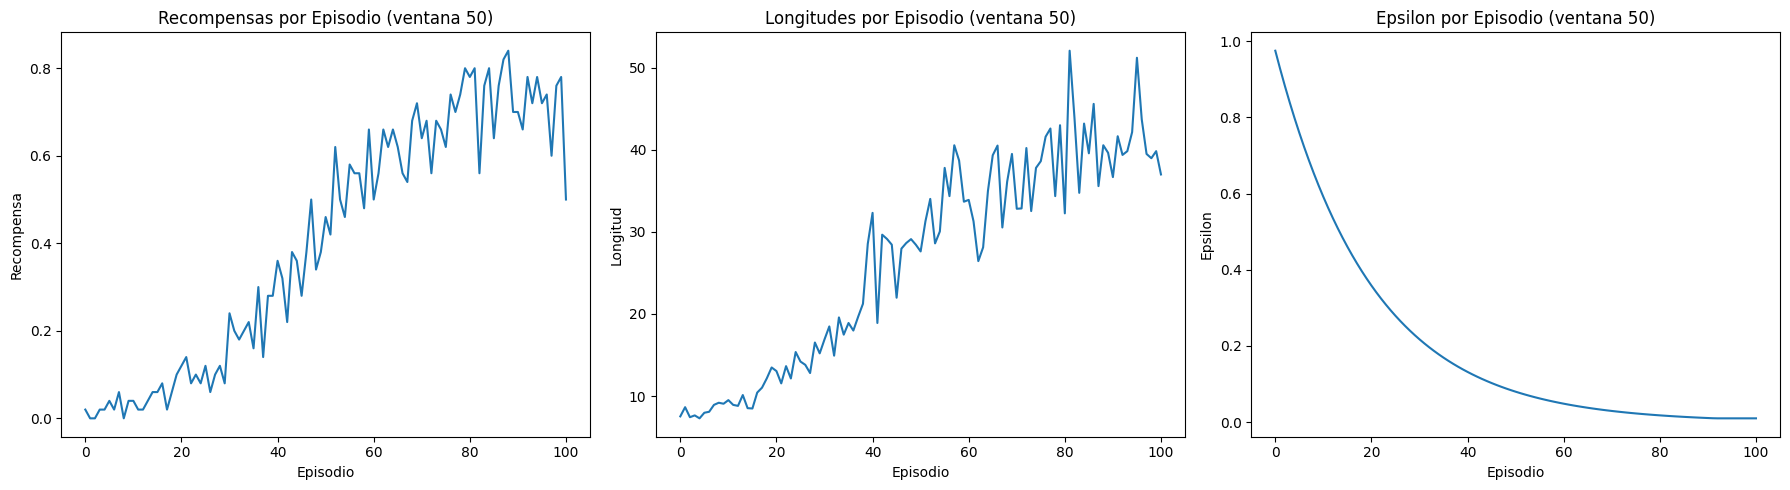

Q-table guardada en qtable_frozenlake_4x4.npy


In [32]:
# Entrenar  el Agente Q-Learning en FrozenLake-v1 4x4 
decay_rate = 0.999
eps_min = 0.01
# decay_rate^episodios = eps_min  -> episodios = log(eps_min/1.0) / log(decay)
episodios = int(np.log(eps_min) / np.log(decay_rate))  + 400 #(5000) para que epsilon llegue a eps_min, más extra de redondeo y verificar como sigue con un seudo evaluar

env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="ansi",  max_episode_steps=500)

#Estrategia de epsilon decay, óptima según experimentos
epsilon_strategy = EpsilonStrExp(epsilon=1.0, epsilon_min=eps_min, decay_rate=decay_rate)
agente = AgenteQLearning(env.observation_space, env.action_space, gamma=1, alpha=0.05, epsilon_strategy=epsilon_strategy)
estado, _ = env.reset()
resultados, longitudes, epsilons = entrenar_agente(agente, env, num_episodios=episodios, verbose=False)
graficar_resultados(resultados, longitudes, epsilons)
ventana = episodios // 100  
# Promediamos resultados, longitudes y epsilons
resultados_prom = promediar_por_bloques(resultados, ventana)
longitudes_prom = promediar_por_bloques(longitudes, ventana)
epsilons_prom = promediar_por_bloques(epsilons, ventana)
graficar_resultados(resultados_prom, longitudes_prom, epsilons_prom, ventana=ventana)
#agente.imprimirQtable()
agente.guardar_qtable("qtable_frozenlake_4x4.npy")
env.close()

<h2 style="color: #228B22;">Evaluar Agente QL tabular</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

In [33]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
agente = AgenteQLearning(env.observation_space, env.action_space)
estado, _ = env.reset()
print(f"FrozenLake-v1 4x4: {env.render()}")
agente.cargar_qtable("qtable_frozenlake_4x4.npy")
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente Q-Learning")
agente.mostrar_policy(env)
env.close()

FrozenLake-v1 4x4: 
SFFF
FHFH
FFFH
HFFG

Q-table cargada desde qtable_frozenlake_4x4.npy

Agente Q-Learning - Resultados de Evaluación:
Tasa de Victorias: 77.6%
Recompensa Promedio: 0.776
Desviación Estándar: 0.417
Total de Victorias: 776
Policy aprendida:
S ↑ ← ↓
← H ← H
↑ ↓ ← H
H → ↓ G


<h2 style="color: #f53b3bff;">Testeo de Hiperparámetros - Q Tabular</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8 </h3>

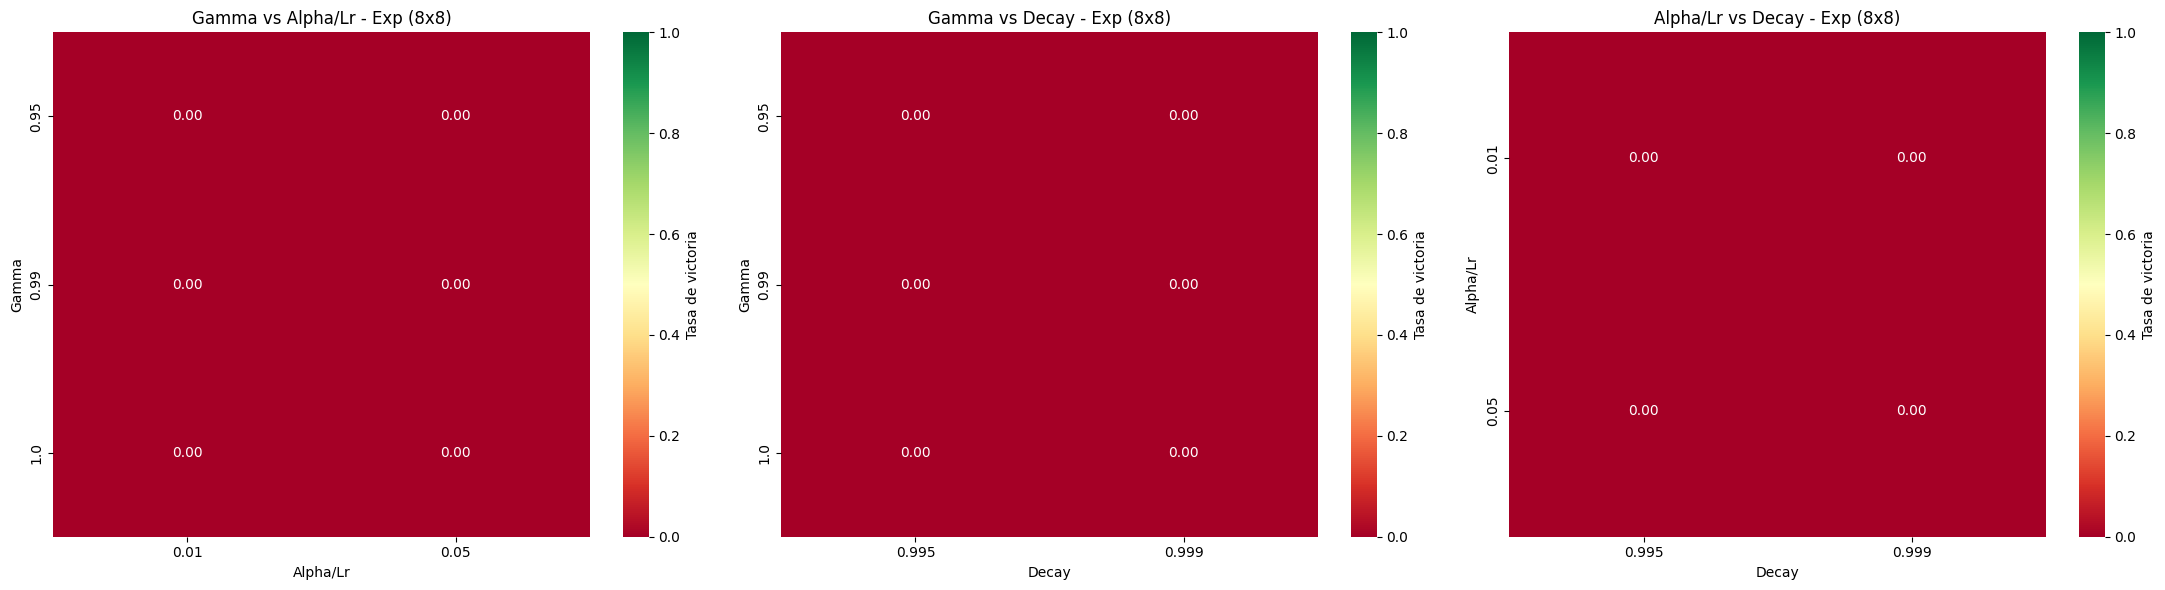

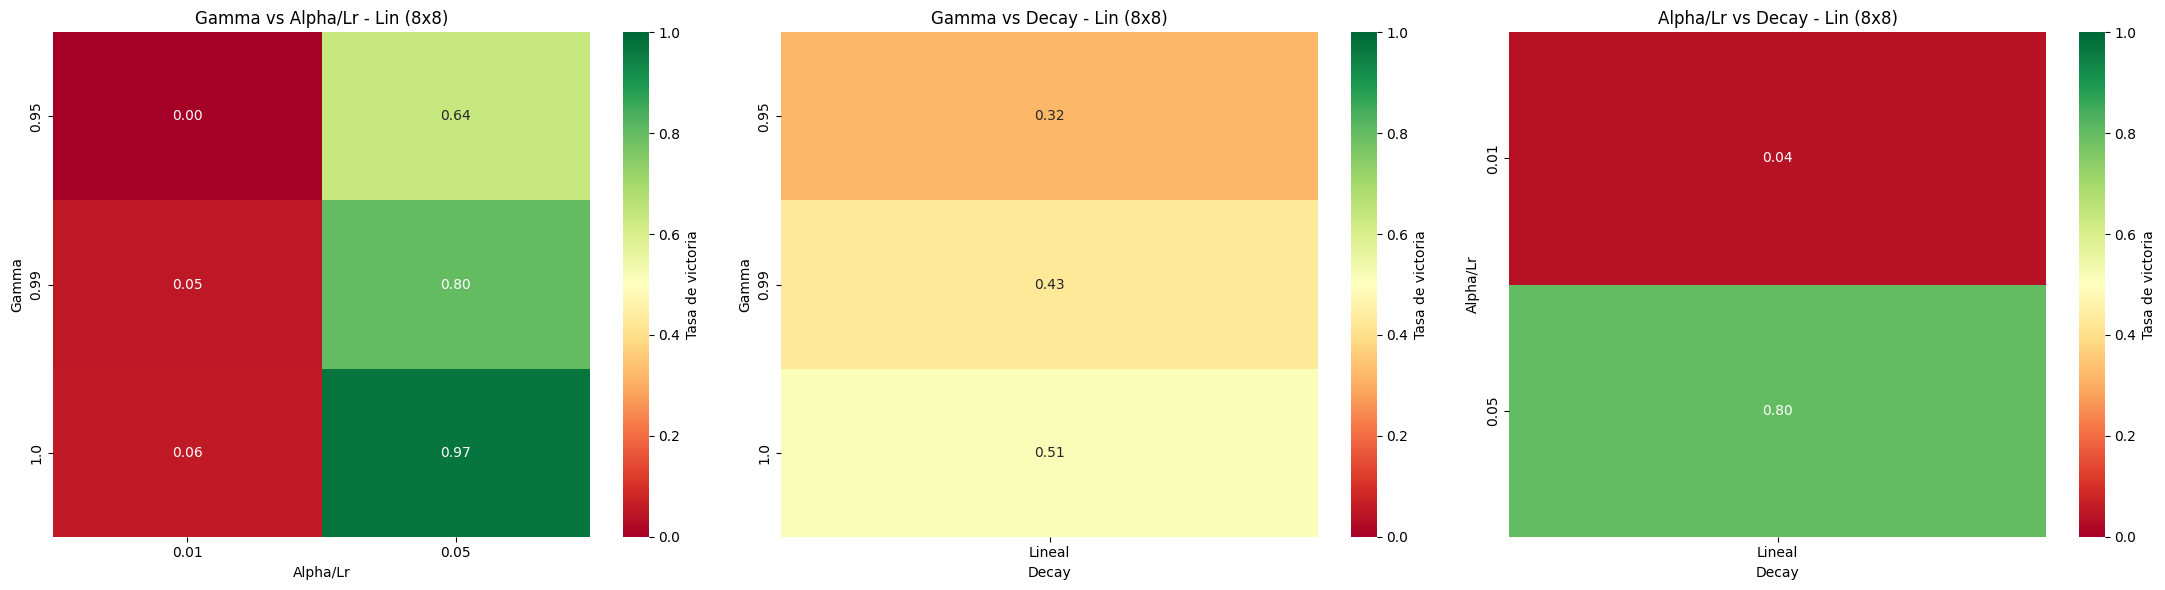


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha/Lr  Decay  Gamma  Tasa de victoria  Recompensa promedio  Desviación estándar
Exponencial     0.010  0.999  0.990             0.000                0.000                0.000
Exponencial     0.050  0.999  1.000             0.000                0.000                0.000
Exponencial     0.010  0.999  1.000             0.000                0.000                0.000
Exponencial     0.010  0.999  0.950             0.000                0.000                0.000
Exponencial     0.010  0.995  0.950             0.000                0.000                0.000
Exponencial     0.010  0.995  1.000             0.000                0.000                0.000
Exponencial     0.050  0.995  1.000             0.000                0.000                0.000
Exponencial     0.010  0.995  0.990             0.000                0.000                0.000
Exponencial     0.050  0.995  0.990             0.000                0.000                0.000


In [33]:
alphas = [0.01, 0.05]
decays = [0.995, 0.999]
gammas = [1.0, 0.99, 0.95]
episodios_train = 8000 #sucede que la lineal es mejor estrategia, por tanto maś episodios se estabiliza mejor
episodios_eval = 100
map_name = "8x8"

df_exp, df_lin = test_params("Q", alphas, decays, gammas, episodios_train, episodios_eval, map_name)

obtener_heatmap(df_exp, df_lin, map_name, valores="Tasa de victoria")


# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))



<h2 style="color: #228B22;">Entrenar Agente QL tabular</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

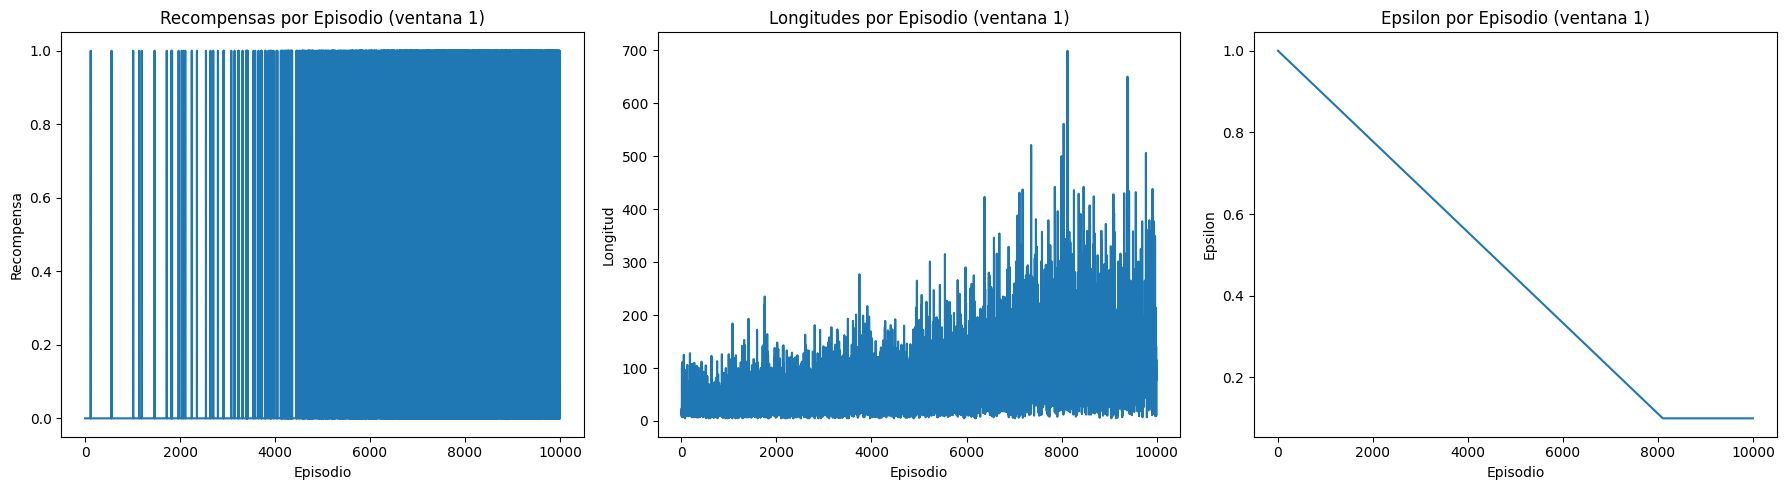

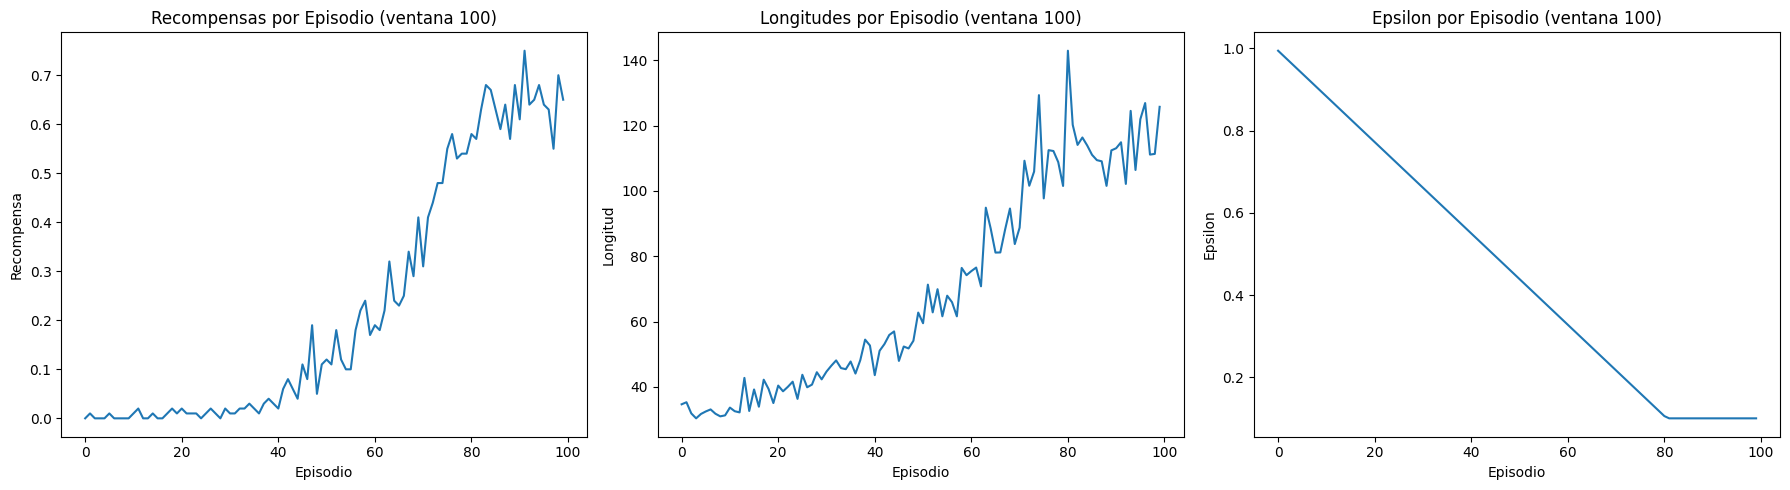

Q-table guardada en qtable_frozenlake_8x8.npy


In [31]:
# Entrenar  Agente Q-Learning en FrozenLake-v1 8x8
decay_steps = 9000
eps_min = 0.1
episodios = decay_steps + 1000
max_episode_steps = 1000

env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, render_mode="ansi",  max_episode_steps=max_episode_steps)

#Estrategia de epsilon decay, óptima según experimentos
epsilon_strategy = EpsilonStrLinear(epsilon=1.0, epsilon_min=eps_min, decay_steps=decay_steps)
agente = AgenteQLearning(env.observation_space, env.action_space, gamma=1, alpha=0.05, epsilon_strategy=epsilon_strategy)
estado, _ = env.reset()
resultados, longitudes, epsilons = entrenar_agente(agente, env, num_episodios=episodios, verbose=False, max_pasos=max_episode_steps)
graficar_resultados(resultados, longitudes, epsilons)
ventana = episodios // 100  
# Promediamos resultados, longitudes y epsilons
resultados_prom = promediar_por_bloques(resultados, ventana)
longitudes_prom = promediar_por_bloques(longitudes, ventana)
epsilons_prom = promediar_por_bloques(epsilons, ventana)
graficar_resultados(resultados_prom, longitudes_prom, epsilons_prom, ventana=ventana)

#agente.imprimirQtable()
agente.guardar_qtable("qtable_frozenlake_8x8.npy")
env.close()

<h2 style="color: #228B22;">Evaluar Agente QL tabular</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

In [32]:
env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, render_mode="ansi",  max_episode_steps=1000)
agente = AgenteQLearning(env.observation_space, env.action_space)
estado, _ = env.reset()
print(f"FrozenLake-v1 8x8: {env.render()}")
agente.cargar_qtable("qtable_frozenlake_8x8.npy")
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente Q-Learning")
agente.mostrar_policy(env)
env.close()

FrozenLake-v1 8x8: 
SFFFFFFF
FFFFFFFF
FFFHFFFF
FFFFFHFF
FFFHFFFF
FHHFFFHF
FHFFHFHF
FFFHFFFG

Q-table cargada desde qtable_frozenlake_8x8.npy

Agente Q-Learning - Resultados de Evaluación:
Tasa de Victorias: 100.0%
Recompensa Promedio: 1.000
Desviación Estándar: 0.000
Total de Victorias: 1000
Policy aprendida:
S ↑ → → → → → →
↑ ↑ ↑ ↑ ↑ ↑ ↑ →
↑ ↑ ← H → ↑ ↑ →
↑ ↑ ↑ ↓ ← H → →
↑ ↑ ↑ H → ↓ ↑ →
← H H ↑ ↑ ↑ H →
→ H ← ↑ H ← H →
↑ ← ↑ H ← ↓ → G

Agente Q-Learning - Resultados de Evaluación:
Tasa de Victorias: 100.0%
Recompensa Promedio: 1.000
Desviación Estándar: 0.000
Total de Victorias: 1000
Policy aprendida:
S ↑ → → → → → →
↑ ↑ ↑ ↑ ↑ ↑ ↑ →
↑ ↑ ← H → ↑ ↑ →
↑ ↑ ↑ ↓ ← H → →
↑ ↑ ↑ H → ↓ ↑ →
← H H ↑ ↑ ↑ H →
→ H ← ↑ H ← H →
↑ ← ↑ H ← ↓ → G


<h2 style="color: #f53b3bff;">Testeo de Hiperparámetros - DQN</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4 con Episodios Reducidos</h3>

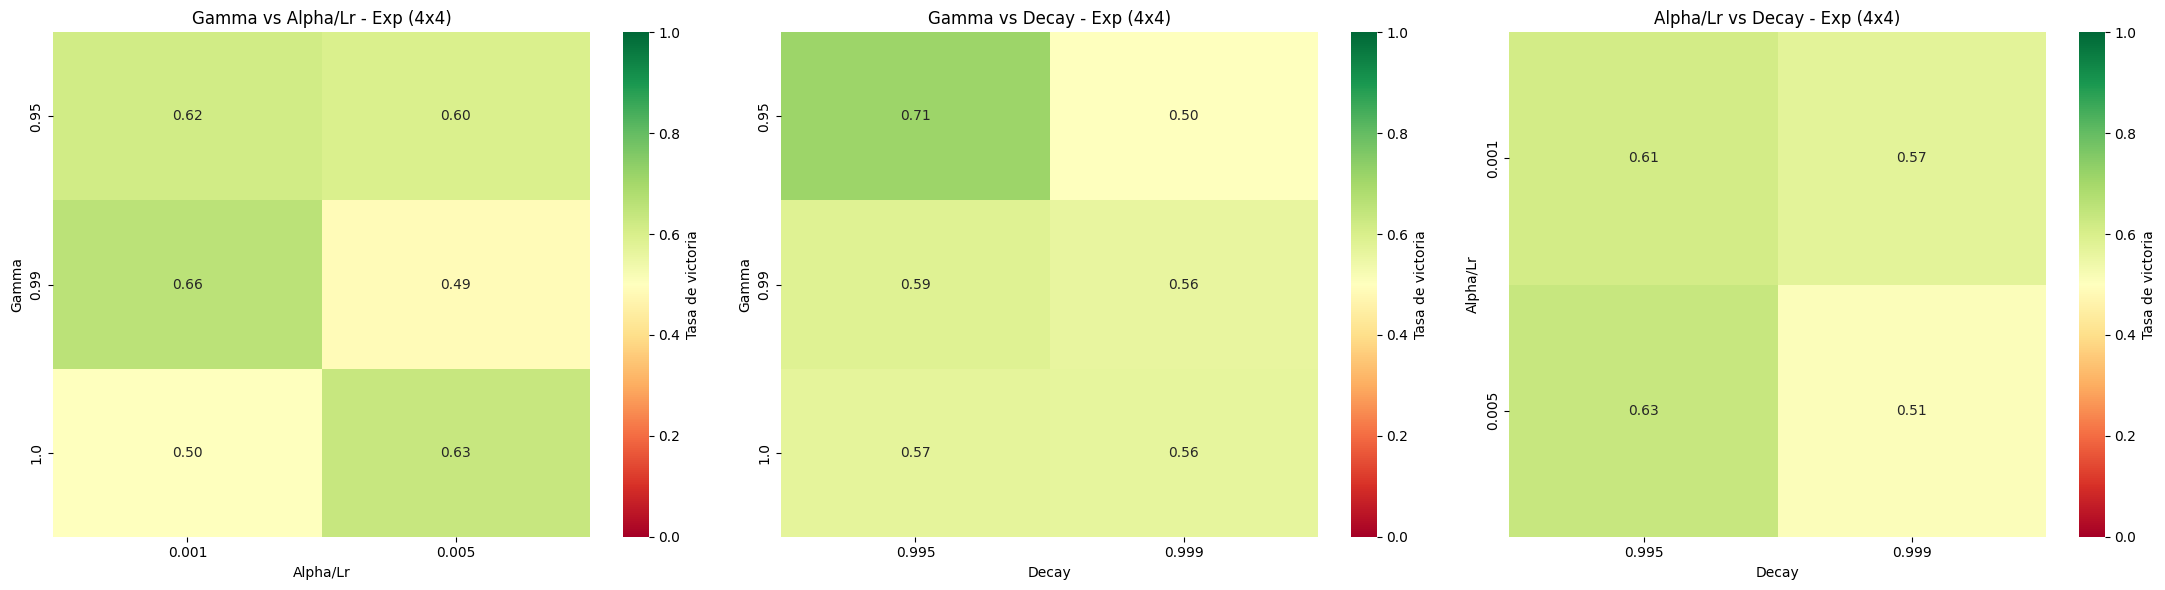

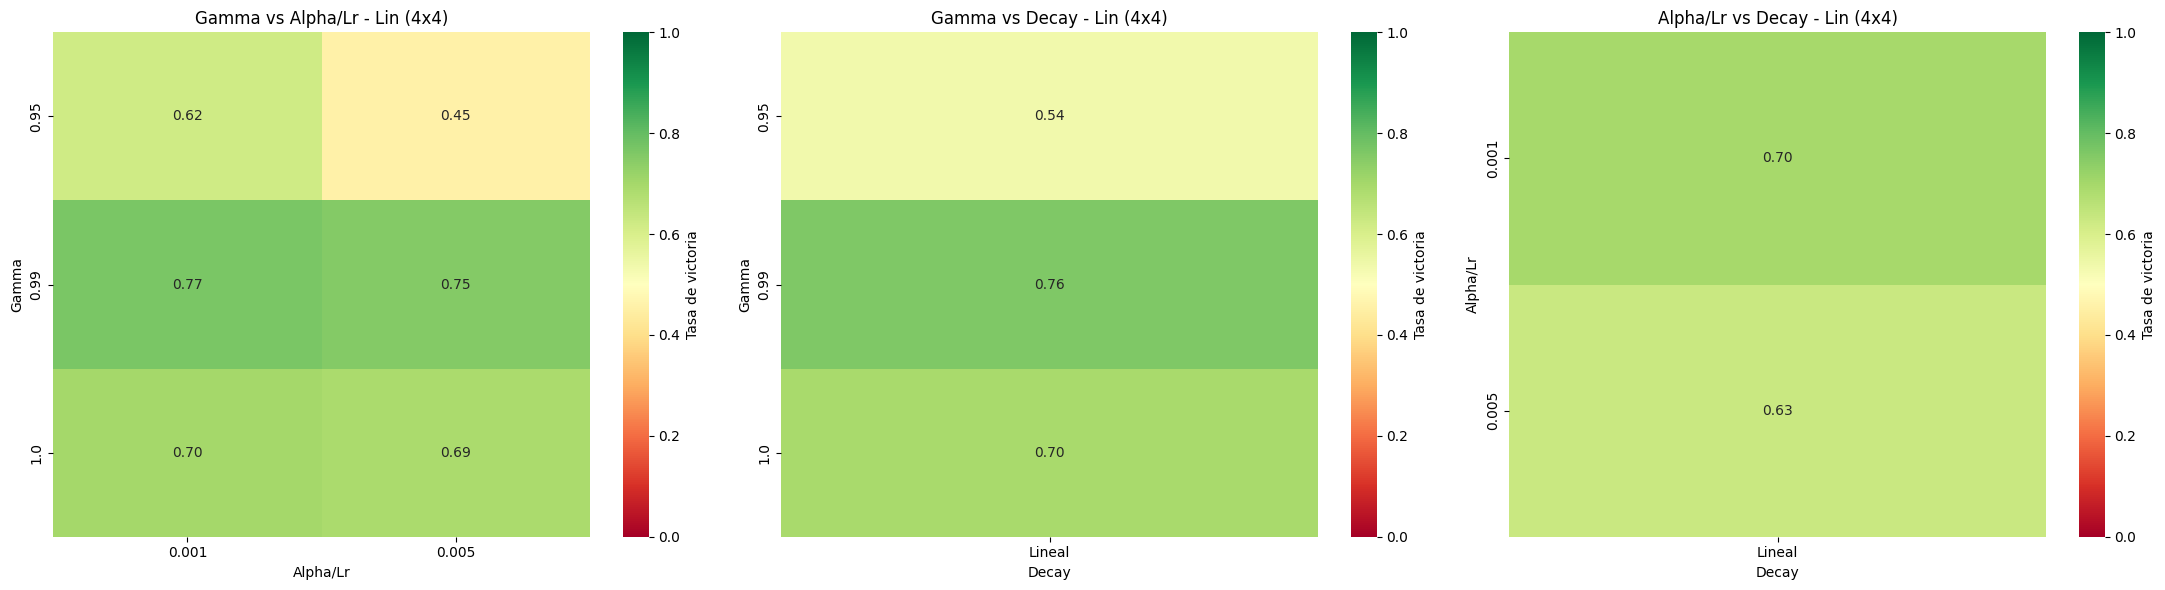


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha/Lr  Decay  Gamma  Tasa de victoria  Recompensa promedio  Desviación estándar  Tamano oculto
Exponencial     0.001  0.999  0.990             0.610                0.610                0.488             16
Exponencial     0.001  0.999  1.000             0.582                0.582                0.493             32
Exponencial     0.001  0.999  0.990             0.554                0.554                0.497             32
Exponencial     0.001  0.999  1.000             0.610                0.610                0.488             16
Exponencial     0.001  0.999  0.950             0.606                0.606                0.489             16
Exponencial     0.001  0.995  1.000             0.742                0.742                0.438             16
Exponencial     0.001  0.995  0.990             0.776                0.776                0.417             32
Exponencial     0.001  0.999  0.950             0.468                0.4

In [26]:
lrs = [0.001, 0.005]
decays = [0.995, 0.999]
gammas = [1.0, 0.99, 0.95]
tamanos_ocultos = [16,32]
episodios_train = 3000
episodios_eval = 500
map_name = "4x4"

df_exp, df_lin = test_params("DQN", lrs, decays, gammas, episodios_train, episodios_eval, map_name, tamanos_ocultos=tamanos_ocultos)
obtener_heatmap(df_exp, df_lin, map_name, valores="Tasa de victoria")


# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))

#IMPRIME RESULTADOS SEGUN ULTIMO TAMANO_OCULTO (32), en dataframes se encuentran todos


<h2 style="color: #e66666ff;">Entrenar Agente DQN</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

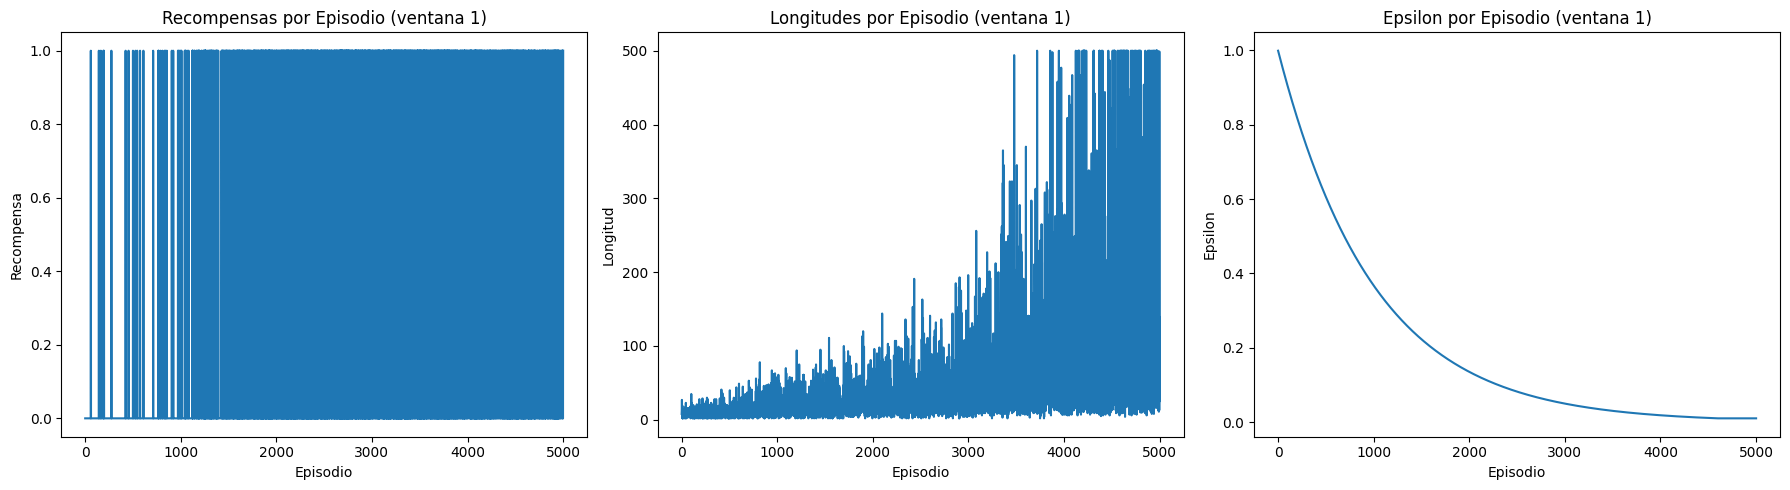

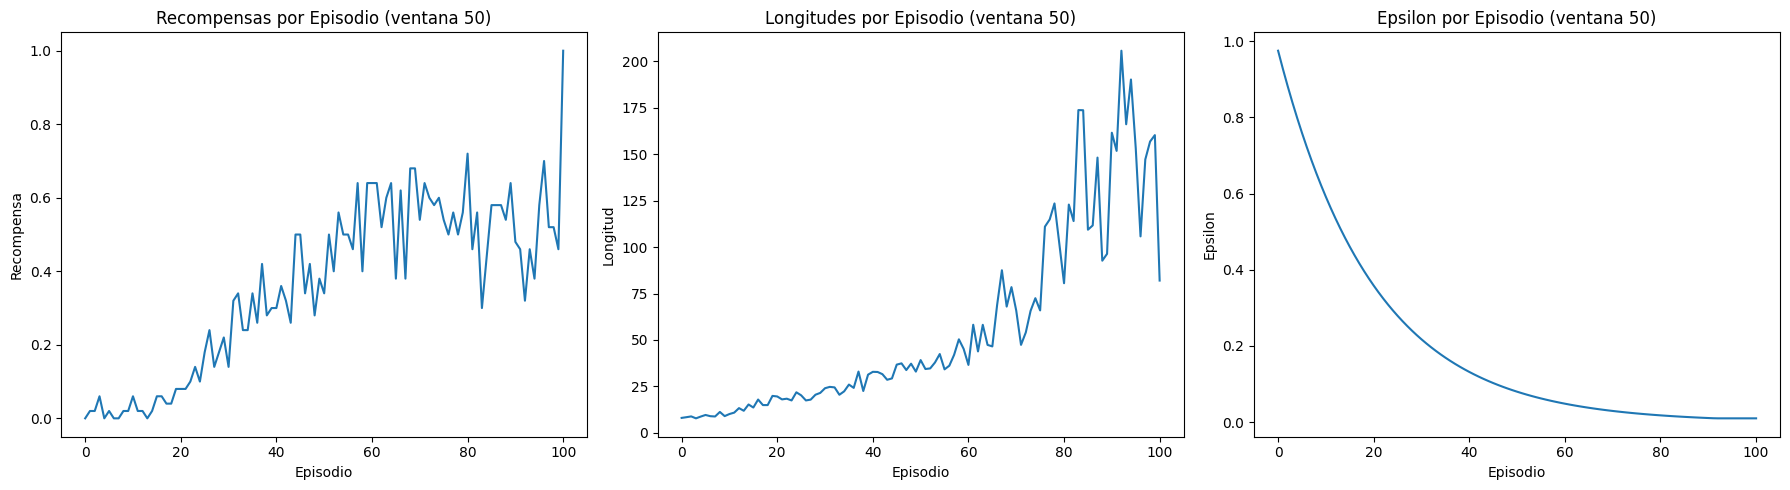

Policy guardada en dqn_policy_frozenlake_4x4.pth


In [36]:
# Entrenar y Evaluar el Agente DQN en FrozenLake-v1 4x4 
decay_rate = 0.999
eps_min = 0.01
# decay_rate^episodios = eps_min  -> episodios = log(eps_min/1.0) / log(decay)
episodios = int(np.log(eps_min) / np.log(decay_rate)) + 400 #(5000) para que epsilon llegue a eps_min, más extra de redondeo y verificar como sigue con un seudo evaluar 

#Estrategia de epsilon decay, óptima según experimentos
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True,  max_episode_steps=500)
epsilon_strategy = EpsilonStrExp(epsilon=1.0, epsilon_min=eps_min, decay_rate=decay_rate)
#epsilon_strategy = EpsilonStrLinear(epsilon=1.0, epsilon_min=eps_min,decay_steps=episodios-1000)
agente = AgenteDQN(
    espacio_estados=env.observation_space,
    espacio_acciones=env.action_space,
    gamma=1,
    tamano_oculto=16,          
    lr=1e-3,                 
    epsilon_strategy=epsilon_strategy
)
estado, _ = env.reset()
resultados, longitudes, epsilons = entrenar_agente(agente, env, num_episodios=episodios, verbose=False, max_pasos=500)
graficar_resultados(resultados, longitudes, epsilons)
ventana = episodios // 100  
# Promediamos resultados, longitudes y epsilons
resultados_prom = promediar_por_bloques(resultados, ventana)
longitudes_prom = promediar_por_bloques(longitudes, ventana)
epsilons_prom = promediar_por_bloques(epsilons, ventana)
graficar_resultados(resultados_prom, longitudes_prom, epsilons_prom, ventana=ventana)

#agente.imprimirQtable()
agente.guardar_policy("dqn_policy_frozenlake_4x4.pth")
env.close()

<h2 style="color: #e66666ff;">Evaluar Agente DQN</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

In [37]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True,  max_episode_steps=500)
agente = AgenteDQN(env.observation_space, env.action_space, tamano_oculto=16)
agente.cargar_policy("dqn_policy_frozenlake_4x4.pth")
estado, _ = env.reset()
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente  DQN")
agente.mostrar_policy(env)
env.close()

Policy cargada desde dqn_policy_frozenlake_4x4.pth

Agente  DQN - Resultados de Evaluación:
Tasa de Victorias: 83.2%
Recompensa Promedio: 0.832
Desviación Estándar: 0.374
Total de Victorias: 832
Policy aprendida (DQN):
S ↑ ↑ ↑
← H ← H
↑ ↓ ← H
H → ↓ G


<h2 style="color: #f53b3bff;">Testeo de Hiperparámetros - DQN</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8 con Episodios Reducidos</h3>


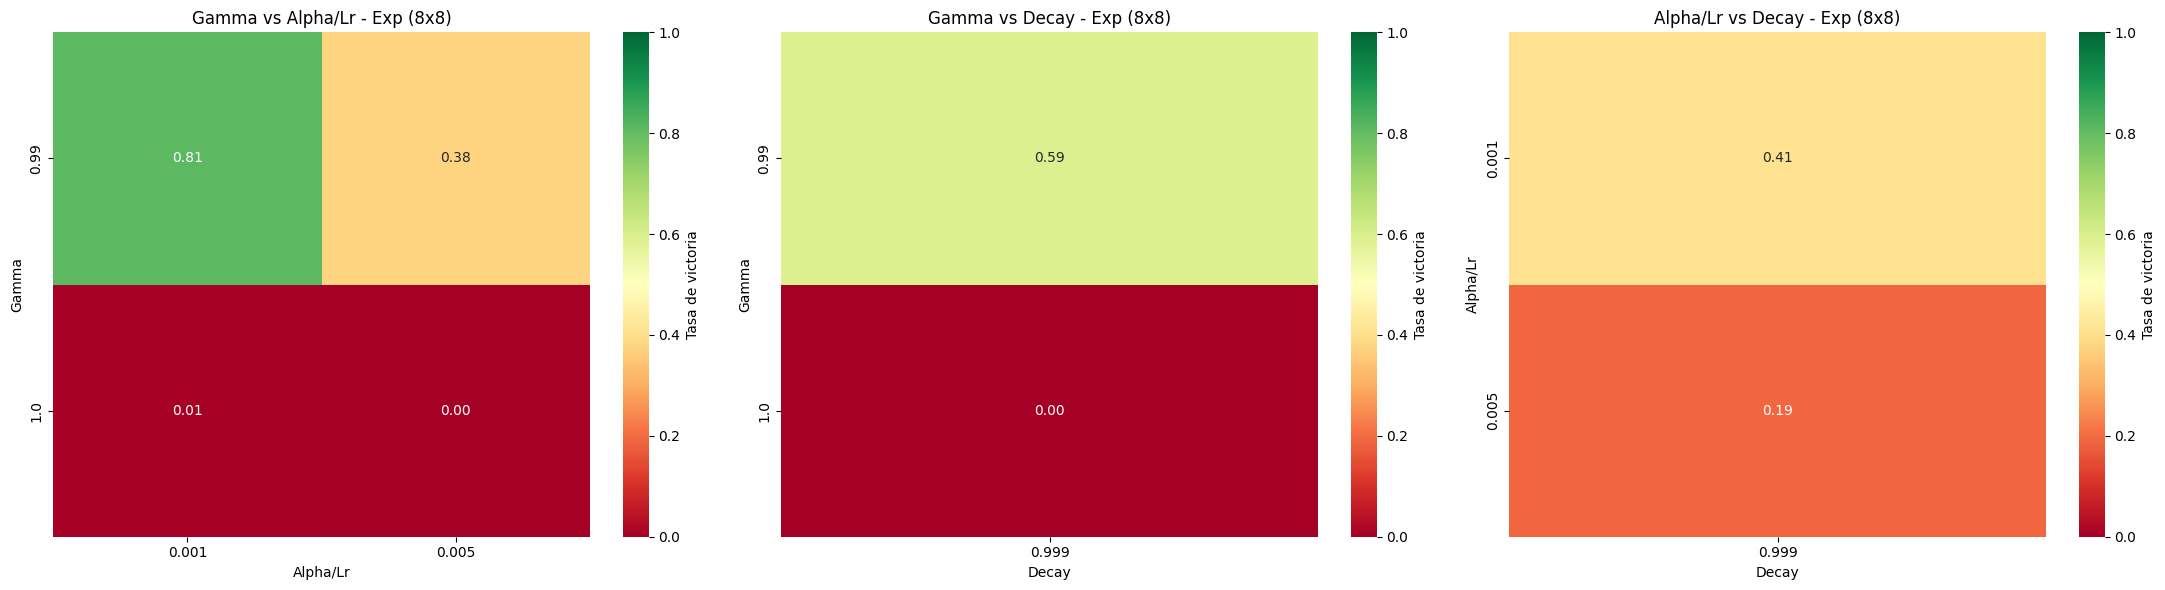

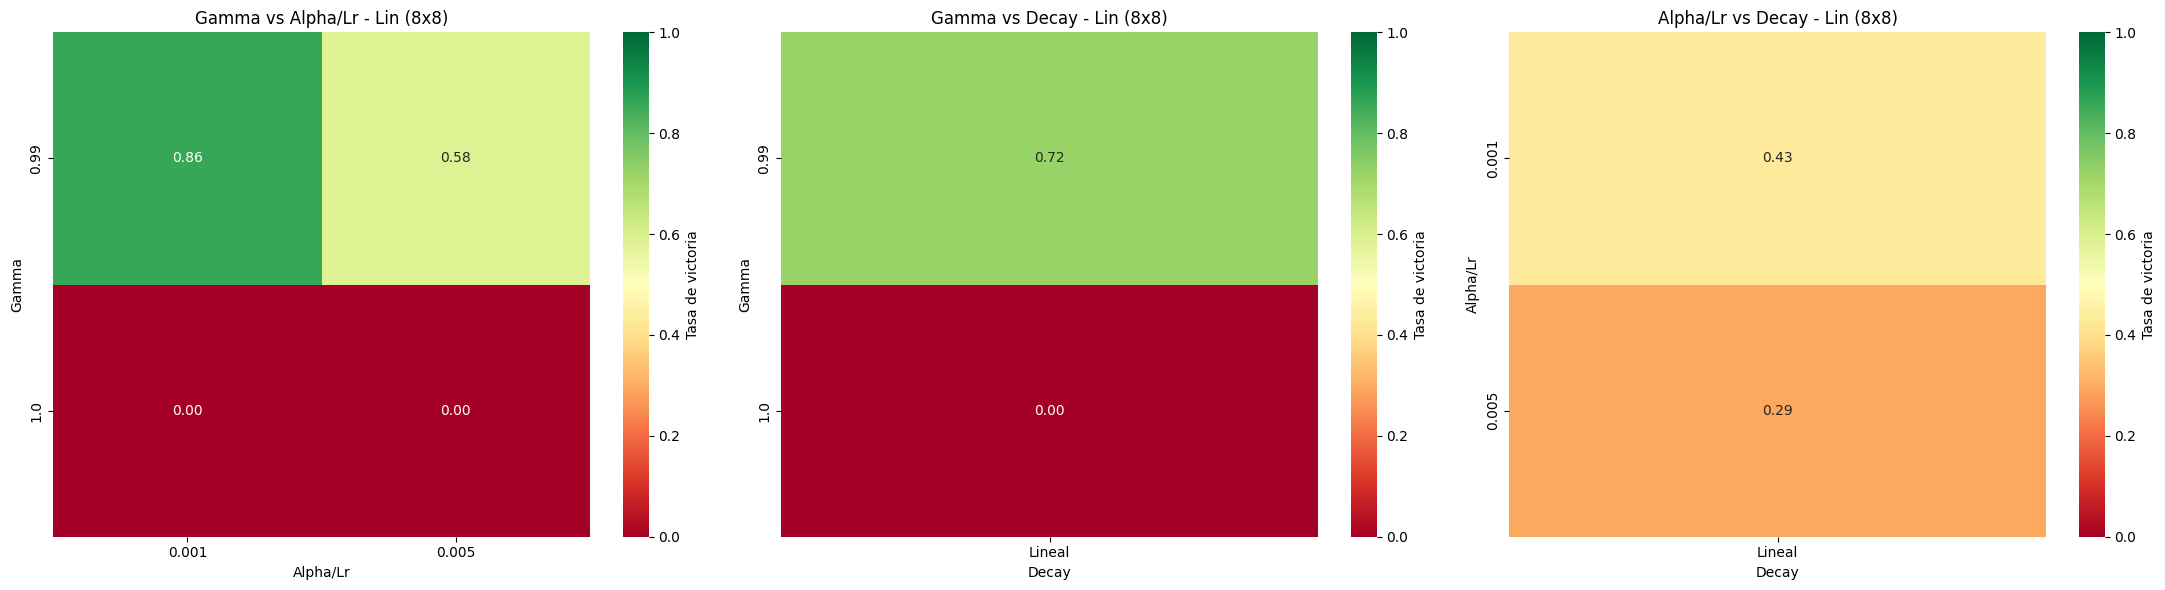


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha/Lr  Decay  Gamma  Tasa de victoria  Recompensa promedio  Desviación estándar  Tamano oculto
Exponencial     0.001  0.999  0.990             0.790                0.790                0.407             64
Exponencial     0.001  0.999  0.990             0.830                0.830                0.376             32
Exponencial     0.005  0.999  0.990             0.620                0.620                0.485             32
Exponencial     0.005  0.999  0.990             0.130                0.130                0.336             64
Exponencial     0.001  0.999  1.000             0.000                0.000                0.000             64
Exponencial     0.005  0.999  1.000             0.000                0.000                0.000             64
Exponencial     0.001  0.999  1.000             0.010                0.010                0.099             32
Exponencial     0.005  0.999  1.000             0.000                0.0

In [29]:
lrs = [0.001, 0.005]
decays = [0.999]
gammas = [1.0, 0.99]
tamanos_ocultos = [32,64]
episodios_train = 3000
episodios_eval = 100
map_name = "8x8"

df_exp, df_lin = test_params("DQN", lrs, decays, gammas, episodios_train, episodios_eval, map_name, tamanos_ocultos=tamanos_ocultos)
obtener_heatmap(df_exp, df_lin, map_name, valores="Tasa de victoria")


# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))

#IMPRIME RESULTADOS SEGUN ULTIMO TAMANO_OCULTO (64), en dataframes se encuentran todos


<h2 style="color: #e66666ff;">Entrenar Agente DQN</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

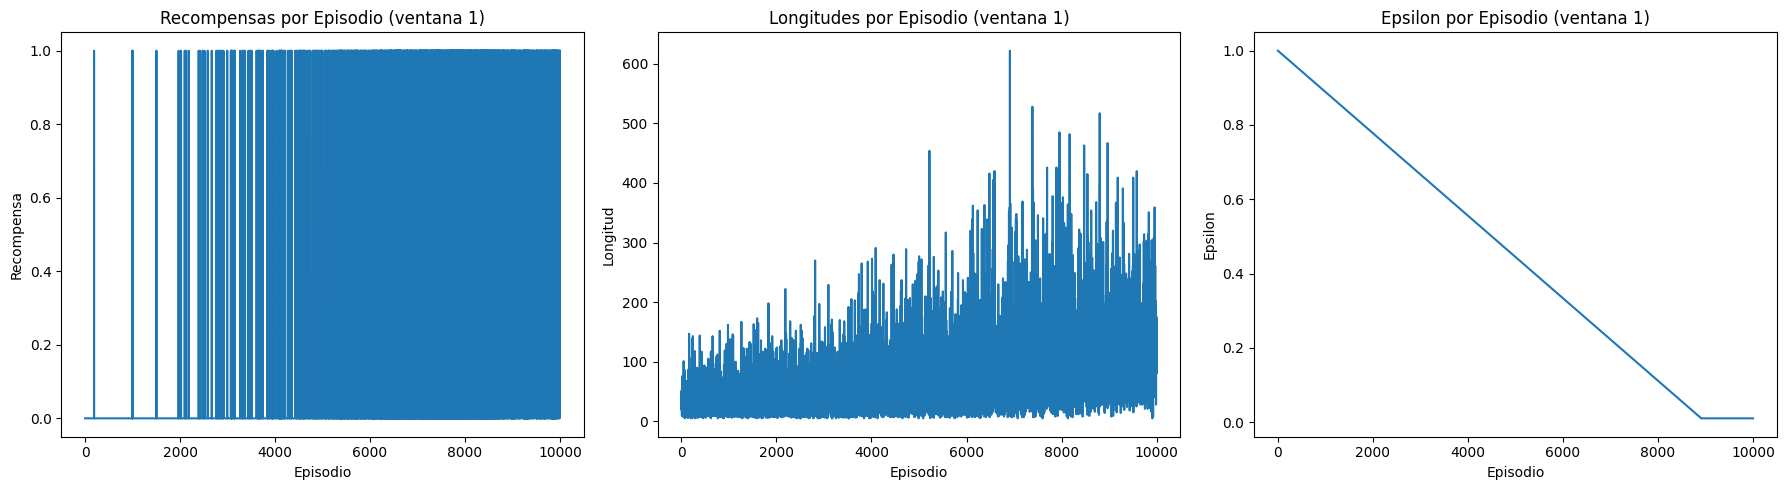

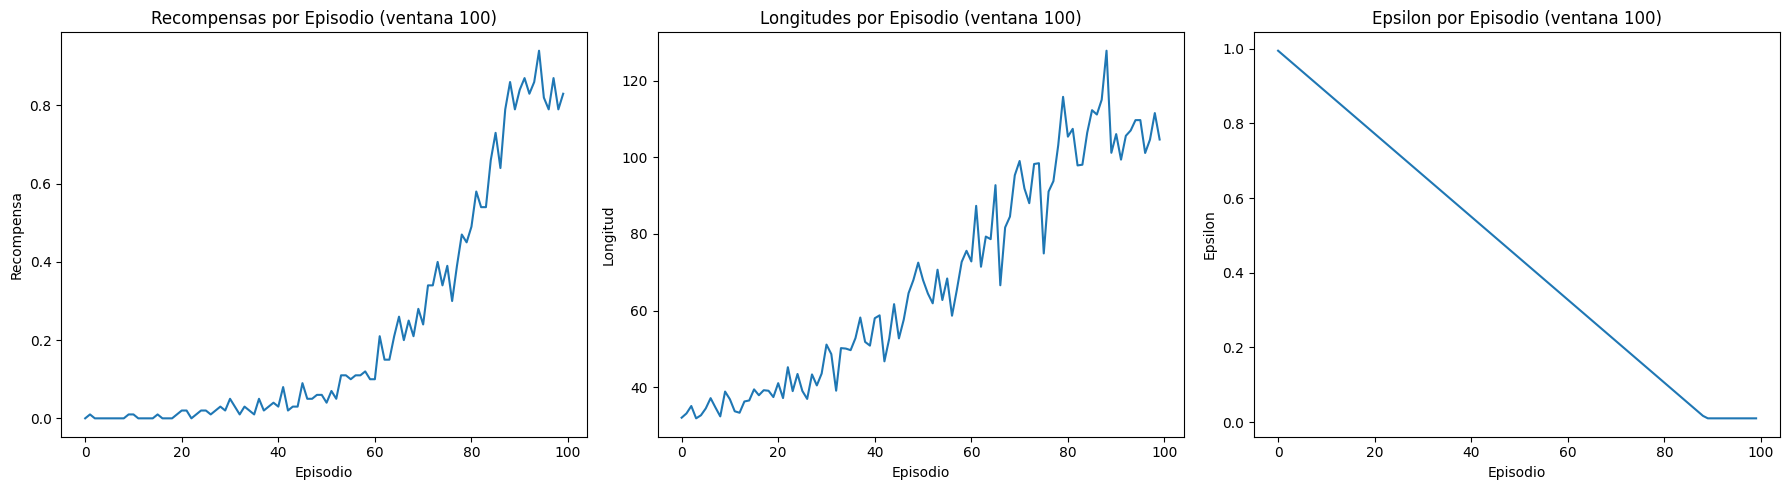

Policy guardada en dqn_policy_frozenlake_8x8.pth


In [35]:
# Entrenar y Evaluar el Agente DQN en FrozenLake-v1 8x8
decay_steps = 9000
eps_min = 0.01
episodios = decay_steps + 1000
max_episode_steps = 1000

env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True,  max_episode_steps=max_episode_steps)

#Estrategia de epsilon decay, óptima según experimentos
epsilon_strategy = EpsilonStrLinear(epsilon=1.0, epsilon_min=eps_min, decay_steps=decay_steps)

agente = AgenteDQN(env.observation_space, env.action_space,lr=1e-3, tamano_oculto=32, gamma=0.99, epsilon_strategy=epsilon_strategy)

estado, _ = env.reset()
resultados, longitudes, epsilons = entrenar_agente(agente, env, num_episodios=episodios, verbose=False, max_pasos=max_episode_steps)
graficar_resultados(resultados, longitudes, epsilons)
ventana = episodios // 100  
# Promediamos resultados, longitudes y epsilons
resultados_prom = promediar_por_bloques(resultados, ventana)
longitudes_prom = promediar_por_bloques(longitudes, ventana)
epsilons_prom = promediar_por_bloques(epsilons, ventana)
graficar_resultados(resultados_prom, longitudes_prom, epsilons_prom, ventana=ventana)

#agente.imprimirQtable()
agente.guardar_policy("dqn_policy_frozenlake_8x8.pth")
env.close()

<h2 style="color: #e66666ff;">Evaluar Agente DQN</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

In [36]:
env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, max_episode_steps=1000)
agente = AgenteDQN(env.observation_space, env.action_space, tamano_oculto=32)
agente.cargar_policy("dqn_policy_frozenlake_8x8.pth")
estado, _ = env.reset()
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente  DQN")
agente.mostrar_policy(env)
env.close()

Policy cargada desde dqn_policy_frozenlake_8x8.pth

Agente  DQN - Resultados de Evaluación:
Tasa de Victorias: 92.9%
Recompensa Promedio: 0.929
Desviación Estándar: 0.257
Total de Victorias: 929
Policy aprendida (DQN):
S ↓ ↓ → → → → →
↑ ↑ ↑ ↑ ↑ ↑ → ↓
↑ ↑ ← H → ↑ → →
↑ ← ↑ ↓ ← H → →
↑ ↑ ↑ H → ↑ ↑ →
← H H ↑ ↑ ← H →
← H ↓ ↑ H ← H →
← ↑ ↑ H → ↑ → G


<h2 style="color: rgba(91, 192, 116, 1);">Visualización de Qtables obtenidas (4x4 y 8x8)</h2>

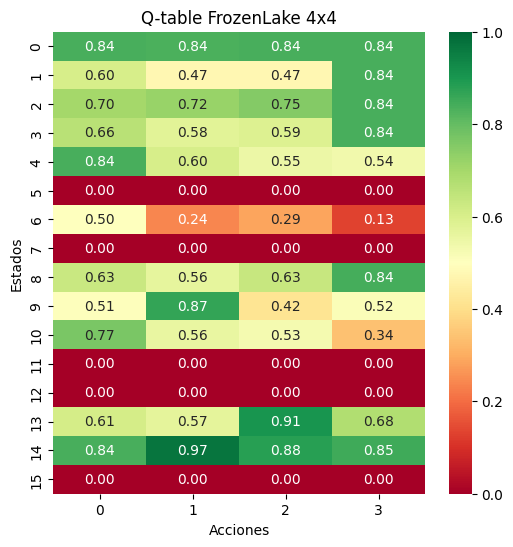

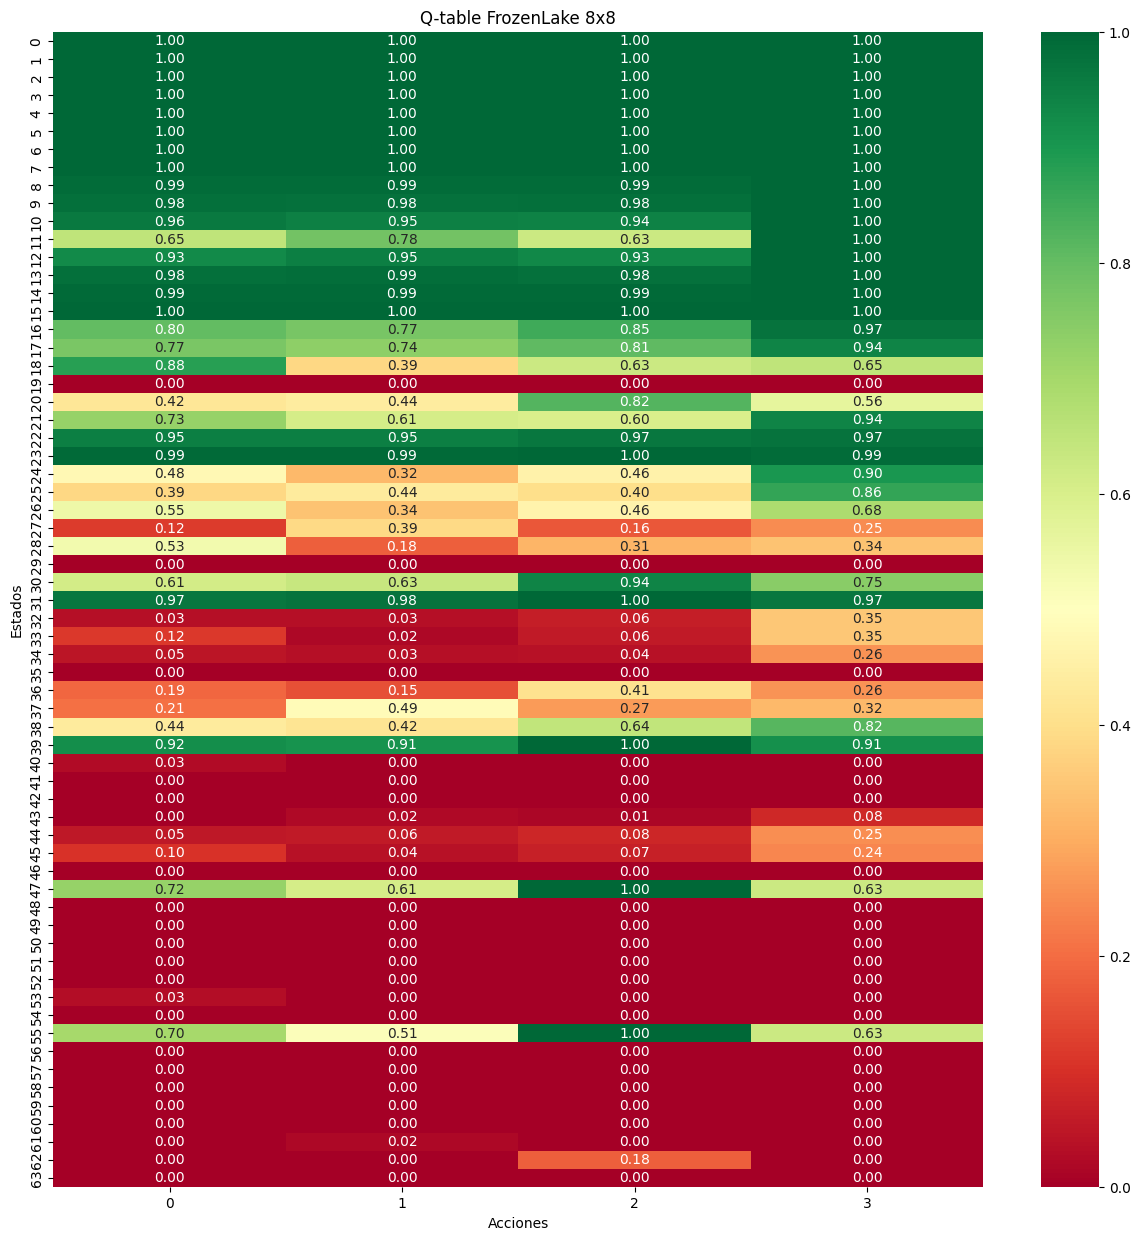

In [37]:
qtable = np.load("qtable_frozenlake_4x4.npy")
#print(qtable) 

# Heatmap
plt.figure(figsize=(6,6))
sns.heatmap(qtable, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0,  vmax=1, annot_kws={"size":10})
plt.title("Q-table FrozenLake 4x4")
plt.xlabel("Acciones")
plt.ylabel("Estados")
plt.show()

qtable = np.load("qtable_frozenlake_8x8.npy")

# Heatmap
plt.figure(figsize=(15,15))  # más ancho y alto
sns.heatmap(qtable, annot=True, cmap="RdYlGn", fmt=".2f", vmin=0,  vmax=1, annot_kws={"size":10})
plt.title("Q-table FrozenLake 8x8")
plt.xlabel("Acciones")
plt.ylabel("Estados")
plt.show()


<h2 style="color: rgba(91, 192, 170, 1);">Visualización de los pesos de la redes neuronales (4x4 y 8x8)</h2>

/tmp/ipykernel_17556/2733832632.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_4x4 = torch.load("dqn_policy_frozenlake_4x4.pth", map_location="cpu")
/tmp/ipykerne

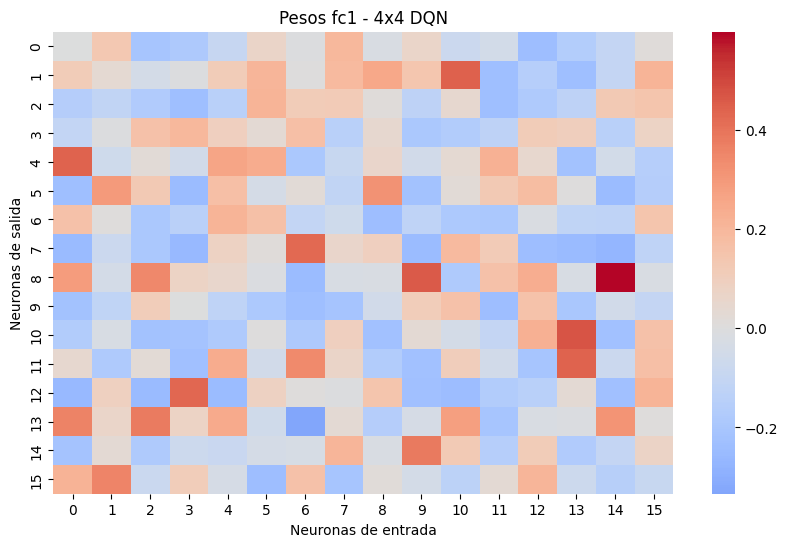

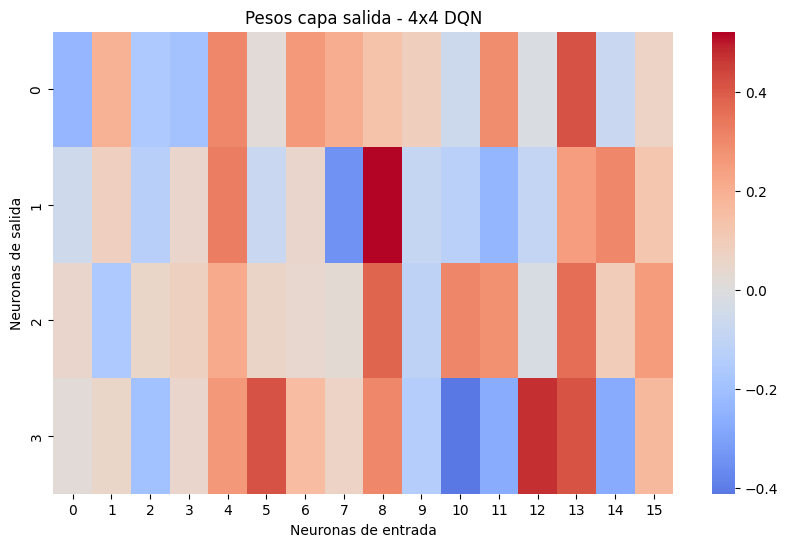

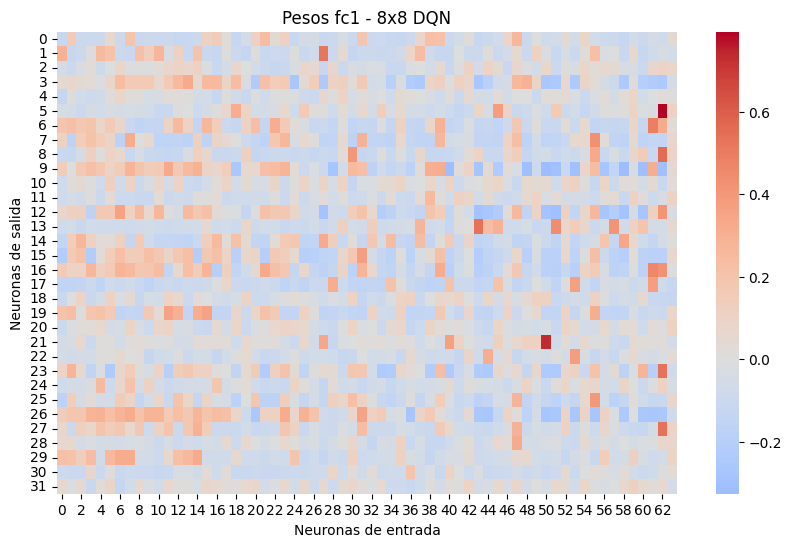

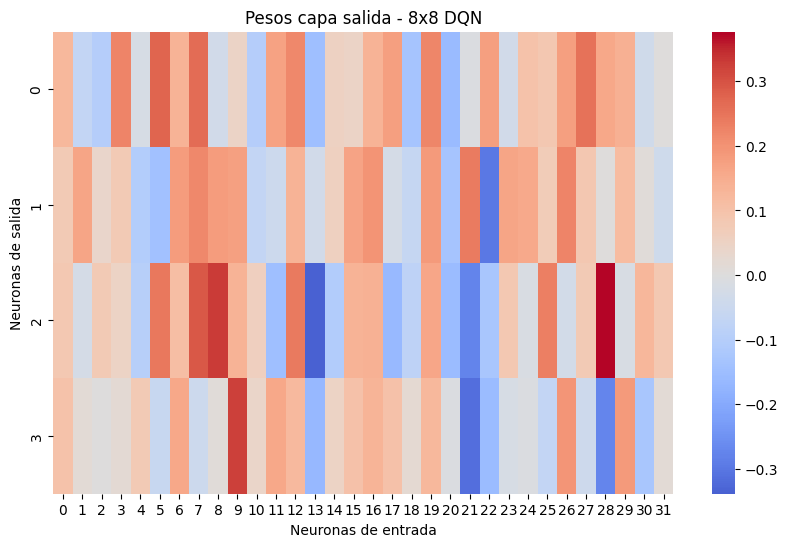

In [38]:
# Cargar state_dict
model_4x4 = torch.load("dqn_policy_frozenlake_4x4.pth", map_location="cpu")
model_8x8 = torch.load("dqn_policy_frozenlake_8x8.pth", map_location="cpu")

def plot_layer_weights(weights, title):
    plt.figure(figsize=(10, 6))
    sns.heatmap(weights.detach().cpu().numpy(), cmap='coolwarm', center=0)
    plt.title(title)
    plt.xlabel("Neuronas de entrada")
    plt.ylabel("Neuronas de salida")
    plt.show()

# 4x4
plot_layer_weights(model_4x4['fc1.weight'], "Pesos fc1 - 4x4 DQN")
plot_layer_weights(model_4x4['out.weight'], "Pesos capa salida - 4x4 DQN")

# 8x8
plot_layer_weights(model_8x8['fc1.weight'], "Pesos fc1 - 8x8 DQN")
plot_layer_weights(model_8x8['out.weight'], "Pesos capa salida - 8x8 DQN")
